# 1. Análisis exploratorio inicial

## 1.1. Origen y contexto de los datos

Se utilizará la base de datos de la **4.ª Encuesta Nacional de Factores de Riesgo (ENFR 2018)**, realizada por el INDEC junto con el Ministerio de Salud y Desarrollo Social de la Nación. Esta encuesta reúne información sobre factores de riesgo y enfermedades no transmisibles en la población adulta argentina.

A continuación, descargamos la base de datos original desde el sitio oficial del INDEC para comenzar el análisis.

In [1]:
import urllib.request
import zipfile
from os import listdir, path
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from scipy.stats import chi2, norm, probplot


In [2]:
# Descargamos el archivo una sola vez para poder reutilizarlo.
url_enfr = "https://www.indec.gob.ar/ftp/cuadros/menusuperior/enfr/ENFR2018_baseusuario.zip"
archivo_zip = "ENFR2018_baseusuario.zip"
carpeta_extraccion = "ENFR2018_datos"

if not path.exists(archivo_zip):
    print("Descargando la base de datos de la ENFR 2018...")
    urllib.request.urlretrieve(url_enfr, archivo_zip)
    print("\n¡Descarga completada!")
else:
    print("¡El archivo ZIP con los datos ya existe en el directorio!")

if not path.exists(carpeta_extraccion):
    print("Extrayendo los archivos...")
    with zipfile.ZipFile(archivo_zip, 'r') as zip_ref:
        zip_ref.extractall(carpeta_extraccion)
    print("¡Archivos extraídos con éxito!")
else:
    print("¡Los archivos ya fueron extraídos previamente!")

# Verificamos qué archivos quedaron disponibles.
lista_archivos_raiz = listdir("./")
lista_archivos_datos = listdir(f"./{carpeta_extraccion}")

print(f"\nEl contenido de la carpeta principal es: {lista_archivos_raiz}")
print(f"El contenido de la carpeta de datos extraída es: {lista_archivos_datos}")


¡El archivo ZIP con los datos ya existe en el directorio!
Extrayendo los archivos...
¡Archivos extraídos con éxito!

El contenido de la carpeta principal es: ['ENFR2018_datos', 'base_replicas_enfr2018.zip', 'ENFR2018_baseusuario.zip', 'TPE.ipynb']
El contenido de la carpeta de datos extraída es: ['ENFR 2018 - Base usuario.txt']


## 1.2. Carga y organización de los datos

Cargamos el archivo original utilizando Pandas y verificamos la cantidad de registros y variables que contiene.

Luego, organizamos las 287 variables en 23 conjuntos temáticos, siguiendo la estructura definida en el manual del INDEC. Esta organización nos permitirá explorar las distintas dimensiones de la encuesta por separado.

In [3]:
# Cargamos la base original y conservamos una copia para trabajar.
ruta_archivo = "ENFR2018_datos/ENFR 2018 - Base usuario.txt"

raw_dataset = pd.read_csv(ruta_archivo, sep='|')

filas = raw_dataset.shape[0]
columnas = raw_dataset.shape[1]
print(f"La base de datos tiene {filas} filas y {columnas} columnas.\n")

df_enfr = raw_dataset.copy()

# Dominios de estimación e información muestral
cols_dominios = [
    'id', 'cod_provincia', 'region', 'tamanio_aglomerado', 'aglomerado', 'localidades_150',
    'submuestra',
]
df_dominios = df_enfr[cols_dominios]

# Bloque hogar

# Características de la vivienda
cols_bh_cv = [
    'bhcv01', 'bhcv02', 'bhcv03', 'bhcv04', 'bhcv05', 'bhcv06', 'bhcv07', 'bhcv08', 'bhcv09',
    'bhcv10', 'bhcv11',
]
df_bh_cv = df_enfr[cols_bh_cv]

# Características del hogar
cols_bh_ho = ['bhho01', 'bhho02', 'bhho03', 'cant_componentes', 'miembros_18', 'tipo_hogar']
df_bh_ho = df_enfr[cols_bh_ho]

# Ingresos del hogar
cols_bh_ih = ['bhih01', 'bhih01_02', 'rango_ingreso', 'quintil_uc', 'imputado', 'bhih03']
df_bh_ih = df_enfr[cols_bh_ih]

# Características de la jefatura del hogar
cols_bh_ch_jefe = [
    'bhch03_j', 'bhch04_j', 'rango_edad_j', 'bhch05_j', 'nivel_instruccion_j',
    'nivel_instruccion_agrupado_j', 'bhch10_01_j', 'bhch10_02_j', 'bhch10_03_j',
    'bhch10_04_j', 'bhch10_05_j', 'bhch10_06_j', 'bhch10_99_j', 'cobertura_salud_j',
]
df_bh_ch_jefe = df_enfr[cols_bh_ch_jefe]

# Situación laboral de la jefatura
cols_bh_sl_jefe = [
    'bhsl01', 'bhsl02', 'bhsl03', 'bhsl04', 'bhsl05', 'bhsl06', 'condicion_actividad_j',
]
df_bh_sl_jefe = df_enfr[cols_bh_sl_jefe]

# Bloque individual: características de la persona seleccionada

# Características sociodemográficas
cols_bi_ch = [
    'bhch02', 'bhch03', 'bhch04', 'rango_edad', 'bhch05', 'nivel_instruccion',
    'nivel_instruccion_agrupado', 'bhch10_01', 'bhch10_02', 'bhch10_03', 'bhch10_04',
    'bhch10_05', 'bhch10_06', 'bhch10_99', 'cobertura_salud',
]
df_bi_ch = df_enfr[cols_bi_ch]

# Paso 1: información declarada en la entrevista

# Situación laboral
cols_bi_sl = [
    'bisl01', 'bisl02', 'bisl03', 'bisl04', 'bisl05', 'bisl06', 'condicion_actividad',
]
df_bi_sl = df_enfr[cols_bi_sl]

# Salud general
cols_bi_sg = ['bisg01', 'bisg02', 'bisg03', 'bisg04', 'bisg05', 'bisg06']
df_bi_sg = df_enfr[cols_bi_sg]

# Actividad física
cols_bi_af = [
    'biaf01', 'biaf02_m', 'biaf02_99', 'biaf03', 'biaf04_m', 'biaf04_99', 'biaf05',
    'biaf06_m', 'biaf06_99', 'biaf07_m', 'biaf07_99', 'biaf08', 'biaf09', 'biaf10_01',
    'biaf10_02', 'biaf10_03', 'biaf10_04', 'nivel_actividad_fisica',
    'barreras_actividad_fisica',
]
df_bi_af = df_enfr[cols_bi_af]

# Tabaco
cols_bi_ta = [
    'bita01', 'bita02', 'bita02_99', 'bita03', 'bita04', 'bita04_01', 'bita04_02', 'bita05',
    'bita06_a', 'bita06_b', 'bita06_b_99', 'bita06_c', 'bita06_d', 'bita07', 'bita07_99',
    'bita08', 'bita09_01', 'bita09_02', 'bita09_03', 'bita09_04', 'bita09_05', 'bita09_06',
    'bita10_01', 'bita10_02', 'bita10_03', 'bita10_04', 'bita10_05', 'bita10_06', 'bita11',
    'bita12', 'bita13', 'bita14', 'bita15', 'bita16', 'consumo_tabaco_100',
    'ta_paquete_y_armado', 'ta_dejar_fumar', 'ta_otros_productos', 'hta_nofumadores',
    'ta_perc_publicidad', 'ta_percepcion_riesgo', 'imagenes_tabaco',
]
df_bi_ta = df_enfr[cols_bi_ta]

# Hipertensión arterial
cols_bi_ha = [
    'biha01', 'biha02', 'biha03', 'biha04', 'biha05_01', 'biha05_02', 'biha06', 'biha06_99',
    'biha07', 'biha08', 'biha09', 'biha10', 'biha11', 'biha11_99', 'biha12', 'biha13',
    'biha14', 'biha15', 'control_hipertension', 'prevalencia_hipertension',
]
df_bi_ha = df_enfr[cols_bi_ha]

# Peso corporal
cols_bi_pc = [
    'bipc01', 'bipc02', 'bipc03', 'bipc04', 'bipc04_99', 'bipc05', 'bipc05_99', 'imc',
    'imc_categorias',
]
df_bi_pc = df_enfr[cols_bi_pc]

# Alimentación
cols_bi_al = [
    'bial01', 'bial02', 'bial03', 'bial03_99', 'bial04', 'bial04_99', 'bial05', 'bial05_99',
    'bial06', 'bial06_99', 'bial07', 'bial08', 'bial09', 'bial10', 'promedio_fv_diario',
    'consumo_fv', 'barreras_fyv', 'tipo_dieta_razones',
]
df_bi_al = df_enfr[cols_bi_al]

# Colesterol
cols_bi_co = [
    'bico01', 'bico02', 'bico03', 'bico04', 'bico05_01', 'bico05_02', 'control_colesterol',
    'prevalencia_colesterol',
]
df_bi_co = df_enfr[cols_bi_co]

# Consumo de alcohol
cols_bi_ca = [
    'bica01', 'bica02', 'bica03_01', 'bica03_02', 'bica03_99', 'bica04_01_b', 'bica04_01_c',
    'bica04_02_b', 'bica04_02_c', 'bica04_03_b', 'bica04_03_c', 'bica04_04', 'bica05_01_b',
    'bica05_01_c', 'bica05_02_b', 'bica05_02_c', 'bica05_03_b', 'bica05_03_c', 'bica05_04',
    'bica06', 'bica07', 'consumo_regular_riesgo', 'consumo_episodico_excesivo',
]
df_bi_ca = df_enfr[cols_bi_ca]

# Diabetes
cols_bi_di = [
    'bidi01', 'bidi02', 'bidi03', 'bidi04_01', 'bidi04_02', 'bidi04_03', 'bidi05',
    'bidi06_01', 'bidi06_02', 'bidi07', 'bidi08', 'bidi09', 'bidi10', 'bidi11', 'bidi12',
    'bidi13', 'bidi14', 'control_diabetes', 'prevalencia_diabetes',
]
df_bi_di = df_enfr[cols_bi_di]

# Lesiones viales
cols_bi_le = ['bile01', 'bile02', 'bile03']
df_bi_le = df_enfr[cols_bi_le]

# Prácticas preventivas
cols_bi_pp = ['bipp01', 'bipp02', 'bipp03', 'bipp04', 'control_mamografia', 'control_pap']
df_bi_pp = df_enfr[cols_bi_pp]

# Prevención de cáncer colorrectal
cols_bi_cc = ['bicc01_01', 'bicc01_02', 'bicc01_03', 'bicc02', 'bicc03', 'control_colon']
df_bi_cc = df_enfr[cols_bi_cc]

# Paso 2: mediciones físicas
cols_bi_ma = [
    'bima01', 'bima02', 'bima03', 'bima04_01_a', 'bima04_01_b', 'bima04_02_a', 'bima04_02_b',
    'bima04_03_a', 'bima04_03_b', 'promedio_sistolica', 'promedio_diastolica', 'ta_elevada',
    'prevalencia_hipertension_combinada', 'bima06', 'bima07', 'bima09', 'bima10', 'imc_bima',
    'imc_categorias_bima', 'bima12', 'bima13', 'bima14',
]
df_bi_ma = df_enfr[cols_bi_ma]

# Paso 3: mediciones bioquímicas
cols_bi_mq = [
    'bimq01', 'bimq05', 'bimq05_01', 'glucemia_elevada',
    'prevalencia_glucemia_elevada_combinada', 'findrisc', 'bimq06', 'bimq06_01',
    'colesterol_elevado', 'prevalencia_colesterol_combinada',
]
df_bi_mq = df_enfr[cols_bi_mq]

# Factores de expansión de cada paso
cols_expansion = ['wf1p', 'wf2p', 'wf3p']
df_expansion = df_enfr[cols_expansion]


La base de datos tiene 29224 filas y 287 columnas.



## 1.3. Tratamiento inicial de códigos especiales

Identificamos y tratamos los códigos especiales utilizados en la encuesta, como las respuestas «No sabe/No contesta», las situaciones en las que una pregunta no corresponde y los indicadores de respuesta.

Las transformaciones se realizan sobre una copia de la base original, que se conserva sin modificaciones. Al finalizar, mostramos un resumen de los cambios realizados y verificamos que se mantengan todos los registros y variables.

In [4]:
# Reutilizamos los 23 conjuntos para controlar que estén todas las columnas.
dataframes_dict = {
    'dominios': df_dominios,
    'bh_cv': df_bh_cv,
    'bh_ho': df_bh_ho,
    'bh_ih': df_bh_ih,
    'bh_ch_jefe': df_bh_ch_jefe,
    'bh_sl_jefe': df_bh_sl_jefe,
    'bi_ch': df_bi_ch,
    'bi_sl': df_bi_sl,
    'bi_sg': df_bi_sg,
    'bi_af': df_bi_af,
    'bi_ta': df_bi_ta,
    'bi_ha': df_bi_ha,
    'bi_pc': df_bi_pc,
    'bi_al': df_bi_al,
    'bi_co': df_bi_co,
    'bi_ca': df_bi_ca,
    'bi_di': df_bi_di,
    'bi_le': df_bi_le,
    'bi_pp': df_bi_pp,
    'bi_cc': df_bi_cc,
    'bi_ma': df_bi_ma,
    'bi_mq': df_bi_mq,
    'expansion': df_expansion,
}

columnas_agrupadas = [col for df in dataframes_dict.values() for col in df.columns]
assert len(columnas_agrupadas) == len(set(columnas_agrupadas))
assert set(columnas_agrupadas) == set(raw_dataset.columns)

# El código 99 indica Ns/Nc en estas variables.
# Las tres últimas también tienen 99 en la base, aunque el manual no lo documenta.
columnas_ns_nc_99 = [
    # Hogar, ingreso y trabajo
    'bhih01_02', 'rango_ingreso', 'bhih03', 'bhsl06', 'bisl06',
    # Actividad física
    'nivel_actividad_fisica',
    # Tabaco
    'bita03', 'bita06_a', 'bita06_d', 'bita08', 'bita15', 'bita16',
    'ta_dejar_fumar',
    # Hipertensión
    'biha01', 'biha02', 'biha03', 'biha08', 'biha09', 'biha14',
    'biha15', 'control_hipertension', 'prevalencia_hipertension',
    # Peso corporal
    'bipc01', 'imc_categorias',
    # Alimentación
    'bial01', 'bial08', 'bial10', 'consumo_fv',
    # Colesterol
    'bico01', 'bico02', 'bico03', 'control_colesterol',
    'prevalencia_colesterol',
    # Alcohol
    'bica01', 'bica02', 'bica07',
    # Diabetes
    'bidi01', 'bidi02', 'bidi06_01', 'bidi06_02', 'bidi10',
    'bidi11', 'bidi12', 'bidi13', 'bidi14', 'control_diabetes',
    'prevalencia_diabetes',
    # Prácticas preventivas
    'bipp01', 'bipp02', 'bipp03', 'bipp04',
    # Cáncer colorrectal
    'bicc01_01', 'bicc01_02', 'bicc01_03', 'bicc03', 'control_colon',
    # Paso 2
    'imc_categorias_bima',
    # Casos adicionales observados en los datos
    'imagenes_tabaco', 'control_mamografia', 'control_pap',
]

codigos_ns_nc_por_columna = {c: [99] for c in columnas_ns_nc_99}
codigos_ns_nc_por_columna['bhcv05'] = [9, 99]  # Ambos códigos aparecen en los datos.
codigos_ns_nc_por_columna['bidi07'] = [9]

# En estas preguntas, 98 representa una respuesta que no corresponde.
columnas_98_nan = [
    'bita06_a',
    'bita10_01', 'bita10_02', 'bita10_03',
    'bita10_04', 'bita10_05', 'bita10_06',
    'bita11', 'bita14', 'bica06',
    'bile01', 'bile02', 'bile03',
]

# Los indicadores _99 aceptan 1/99; los _98, únicamente 98.
# Los valores vacíos quedan como False.
indicadores_98 = [
    'bica04_01_c', 'bica04_02_c', 'bica04_03_c',
    'bica05_01_c', 'bica05_02_c', 'bica05_03_c',
    'bimq05_01', 'bimq06_01',
]
indicadores_99 = [
    c for c in raw_dataset.columns
    if c.endswith('_99') or c == 'bhch10_99_j'
]

# Comprobamos que ninguna columna reciba tratamientos incompatibles.
assert not (set(indicadores_98) & set(columnas_98_nan))
assert not (set(indicadores_99) & set(codigos_ns_nc_por_columna))
assert not (set(indicadores_98) & set(codigos_ns_nc_por_columna))
assert len(columnas_ns_nc_99) == len(set(columnas_ns_nc_99))
for grupo in (
    codigos_ns_nc_por_columna,
    columnas_98_nan,
    indicadores_98,
    indicadores_99,
):
    assert set(grupo).issubset(raw_dataset.columns)

# Aplicamos las conversiones sobre una copia, sin alterar la base original.
df_enfr_limpio = raw_dataset.copy()
filas_cambios = []

for columna, codigos in codigos_ns_nc_por_columna.items():
    mascara = df_enfr_limpio[columna].isin(codigos)
    filas_cambios.append({
        'Variable': columna,
        'Tratamiento': 'Ns/Nc -> NaN',
        'Cantidad': int(mascara.sum()),
    })
    df_enfr_limpio[columna] = df_enfr_limpio[columna].mask(mascara)

for columna in columnas_98_nan:
    mascara = df_enfr_limpio[columna].eq(98)
    filas_cambios.append({
        'Variable': columna,
        'Tratamiento': '98 -> NaN',
        'Cantidad': int(mascara.sum()),
    })
    df_enfr_limpio[columna] = df_enfr_limpio[columna].mask(mascara)

for columna in indicadores_99:
    observados = set(df_enfr_limpio[columna].dropna().unique())
    inesperados = observados - {1, 99}
    if inesperados:
        raise ValueError(f'{columna}: valores inesperados: {inesperados}')
    df_enfr_limpio[columna] = df_enfr_limpio[columna].isin([1, 99]).astype(bool)

for columna in indicadores_98:
    observados = set(df_enfr_limpio[columna].dropna().unique())
    inesperados = observados - {98}
    if inesperados:
        raise ValueError(f'{columna}: valores inesperados: {inesperados}')
    df_enfr_limpio[columna] = df_enfr_limpio[columna].eq(98).astype(bool)

# Verificamos que el tratamiento no haya quitado filas ni columnas.
assert df_enfr_limpio.shape == raw_dataset.shape
assert df_enfr_limpio.index.equals(raw_dataset.index)
assert df_enfr_limpio.columns.equals(raw_dataset.columns)
for columna in ('bhch04_j', 'bhch04', 'bimq05', 'bimq06'):
    assert df_enfr_limpio[columna].equals(raw_dataset[columna])

# Reconstruimos los conjuntos con las variables ya tratadas.
diccionario_df_limpios = {
    nombre: df_enfr_limpio[df.columns].copy()
    for nombre, df in dataframes_dict.items()
}

# Mostramos el alcance de los cambios realizados.
resumen_limpieza_14 = pd.DataFrame(filas_cambios)
print(f'Bloques procesados: {len(diccionario_df_limpios)}')
print(f'Indicadores _99 transformados a bool: {len(indicadores_99)}')
print(f'Indicadores 98 transformados a bool: {len(indicadores_98)}')
print(
    f'Valores especiales sustituidos por NaN: '
    f'{resumen_limpieza_14["Cantidad"].sum()}'
)
print(f'Registros conservados: {len(df_enfr_limpio)}')
print(f'Columnas conservadas: {len(df_enfr_limpio.columns)}')
display(
    resumen_limpieza_14.query('Cantidad > 0').sort_values(
        'Cantidad', ascending=False
    )
)


Bloques procesados: 23
Indicadores _99 transformados a bool: 18
Indicadores 98 transformados a bool: 8
Valores especiales sustituidos por NaN: 144094
Registros conservados: 29224
Columnas conservadas: 287


,Variable,Tratamiento,Cantidad
72,bile01,98 -> NaN,20354
73,bile02,98 -> NaN,19651
65,bita10_03,98 -> NaN,13337
0,bhih01_02,Ns/Nc -> NaN,12584
66,bita10_04,98 -> NaN,12166
...,...,...,...
54,bicc03,Ns/Nc -> NaN,15
17,biha09,Ns/Nc -> NaN,14
16,biha08,Ns/Nc -> NaN,9
41,bidi11,Ns/Nc -> NaN,9


## 1.4. Exploración de los datos

### 1.4.1. Análisis general de las variables

Realizamos una primera exploración de los 23 conjuntos temáticos para conocer las características de sus variables.

Para cada una mostramos su tipo de dato, cantidad y porcentaje de valores nulos y cantidad de valores únicos. Además, según su naturaleza estadística, presentamos medidas descriptivas para las variables cuantitativas o las categorías más frecuentes para las cualitativas.

Los resultados se presentan en tablas separadas por conjunto temático, ordenadas según la cantidad de valores nulos.

In [5]:
# Separamos las variables cuantitativas de las categorías codificadas con números.
variables_cuantitativas = {
    # Hogar y características personales
    'bhcv02', 'bhho02', 'bhho03', 'cant_componentes', 'miembros_18',
    'bhch04_j', 'bhch04', 'bhih01',

    # Actividad física
    'biaf01', 'biaf02_m', 'biaf03', 'biaf04_m',
    'biaf05', 'biaf06_m', 'biaf07_m',

    # Tabaco, alcohol y alimentación
    'bita02', 'bita06_b', 'bita07',
    'bica03_01', 'bica03_02',
    'bica04_01_b', 'bica04_02_b', 'bica04_03_b',
    'bica05_01_b', 'bica05_02_b', 'bica05_03_b',
    'bial03', 'bial04', 'bial05', 'bial06', 'promedio_fv_diario',

    # Peso, talla, presión arterial y mediciones bioquímicas
    'bipc04', 'bipc05', 'imc', 'bima07', 'bima10', 'imc_bima',
    'bima04_01_a', 'bima04_01_b', 'bima04_02_a', 'bima04_02_b',
    'bima04_03_a', 'bima04_03_b',
    'promedio_sistolica', 'promedio_diastolica', 'bima13',
    'bimq05', 'bimq06',

    # Factores de expansión
    'wf1p', 'wf2p', 'wf3p',
}


def reporte_exploratorio_integral(nombre, df, cuantitativas):
    # Una fila por variable, sin mezclar códigos categóricos con medidas numéricas.
    print(
        f'\n{"=" * 85}\n'
        f'BLOQUE: {nombre.upper()} | '
        f'{len(df)} filas, {len(df.columns)} columnas'
    )

    filas = []

    for col in df.columns:
        s = df[col]
        validos = s.dropna()
        nulos = int(s.isna().sum())

        info = {
            'Variable': col,
            'dtype': str(s.dtype),
            'Nulos': nulos,
            '% nulos': round(100 * nulos / len(s), 2) if len(s) else np.nan,
            'Únicos': int(validos.nunique()),
            'Resumen': '',
            'Mín': np.nan,
            'Mediana': np.nan,
            'Media': np.nan,
            'Máx': np.nan,
        }

        if validos.empty:
            info['Resumen'] = 'Sin datos observados'

        elif col == 'id':
            info['Resumen'] = 'Identificador'

        elif col in cuantitativas and pd.api.types.is_numeric_dtype(s):
            info['Mín'] = round(float(validos.min()), 2)
            info['Mediana'] = round(float(validos.median()), 2)
            info['Media'] = round(float(validos.mean()), 2)
            info['Máx'] = round(float(validos.max()), 2)

        else:
            # Para categorías, mostramos las tres respuestas más frecuentes.
            frecuencias = s.value_counts(normalize=True, dropna=True).head(3)

            info['Resumen'] = 'Frecuencias: ' + '; '.join(
                f'{valor}: {proporcion * 100:.1f}%'
                for valor, proporcion in frecuencias.items()
            )

        filas.append(info)

    resultado = pd.DataFrame(filas).sort_values(
        ['Nulos', 'Variable'], ascending=[False, True]
    )

    display(resultado.reset_index(drop=True))
    return resultado


# Generamos una tabla por conjunto temático.
reportes_eda = {
    nombre: reporte_exploratorio_integral(nombre, df, variables_cuantitativas)
    for nombre, df in diccionario_df_limpios.items()
}



BLOQUE: DOMINIOS | 29224 filas, 7 columnas


,Variable,dtype,Nulos,% nulos,Únicos,Resumen,Mín,Mediana,Media,Máx
0,aglomerado,int64,0,0.0,9,Frecuencias: 9: 77.5%; 1: 12.2%; 2: 2.0%,NaN,NaN,NaN,NaN
1,cod_provincia,int64,0,0.0,24,Frecuencias: 6: 19.1%; 14: 6.8%; 82: 6.1%,NaN,NaN,NaN,NaN
2,id,int64,0,0.0,29224,Identificador,NaN,NaN,NaN,NaN
3,localidades_150,int64,0,0.0,2,Frecuencias: 0: 56.7%; 1: 43.3%,NaN,NaN,NaN,NaN
4,region,int64,0,0.0,6,Frecuencias: 2: 32.1%; 3: 18.7%; 4: 14.5%,NaN,NaN,NaN,NaN
5,submuestra,int64,0,0.0,2,Frecuencias: 1: 74.3%; 0: 25.7%,NaN,NaN,NaN,NaN
6,tamanio_aglomerado,int64,0,0.0,4,Frecuencias: 4: 58.2%; 3: 19.3%; 1: 12.2%,NaN,NaN,NaN,NaN



BLOQUE: BH_CV | 29224 filas, 11 columnas


,Variable,dtype,Nulos,% nulos,Únicos,Resumen,Mín,Mediana,Media,Máx
0,bhcv05,float64,123,0.42,2,Frecuencias: 1.0: 80.4%; 2.0: 19.6%,NaN,NaN,NaN,NaN
1,bhcv10,float64,122,0.42,3,Frecuencias: 1.0: 94.8%; 2.0: 4.3%; 3.0: 1.0%,NaN,NaN,NaN,NaN
2,bhcv11,float64,122,0.42,4,Frecuencias: 1.0: 73.3%; 2.0: 17.7%; 3.0: 8.5%,NaN,NaN,NaN,NaN
3,bhcv01,int64,0,0.00,7,Frecuencias: 1: 84.7%; 3: 13.7%; 2: 1.1%,NaN,NaN,NaN,NaN
4,bhcv02,int64,0,0.00,13,,1.0,3.0,3.14,16.0
5,bhcv03,int64,0,0.00,4,Frecuencias: 1: 85.8%; 2: 13.2%; 3: 0.7%,NaN,NaN,NaN,NaN
6,bhcv04,int64,0,0.00,9,Frecuencias: 4: 41.3%; 1: 24.1%; 2: 23.1%,NaN,NaN,NaN,NaN
7,bhcv06,int64,0,0.00,4,Frecuencias: 1: 56.9%; 2: 41.9%; 4: 0.7%,NaN,NaN,NaN,NaN
8,bhcv07,int64,0,0.00,3,Frecuencias: 1: 95.8%; 2: 3.8%; 3: 0.4%,NaN,NaN,NaN,NaN
9,bhcv08,int64,0,0.00,5,Frecuencias: 1: 95.2%; 2: 3.8%; 4: 0.6%,NaN,NaN,NaN,NaN



BLOQUE: BH_HO | 29224 filas, 6 columnas


,Variable,dtype,Nulos,% nulos,Únicos,Resumen,Mín,Mediana,Media,Máx
0,bhho01,float64,122,0.42,2,Frecuencias: 1.0: 98.8%; 2.0: 1.2%,NaN,NaN,NaN,NaN
1,bhho02,int64,0,0.00,15,,1.0,3.0,3.12,92.0
2,bhho03,int64,0,0.00,9,,1.0,2.0,1.91,10.0
3,cant_componentes,int64,0,0.00,15,,1.0,3.0,2.86,15.0
4,miembros_18,int64,0,0.00,12,,1.0,2.0,2.11,13.0
5,tipo_hogar,int64,0,0.00,8,Frecuencias: 4: 31.1%; 1: 22.7%; 2: 16.3%,NaN,NaN,NaN,NaN


... (36 outputs left out)


BLOQUE: BI_MQ | 29224 filas, 10 columnas


,Variable,dtype,Nulos,% nulos,Únicos,Resumen,Mín,Mediana,Media,Máx
0,prevalencia_colesterol_combinada,float64,25821,88.36,2,Frecuencias: 2.0: 60.4%; 1.0: 39.6%,NaN,NaN,NaN,NaN
1,bimq06,float64,24313,83.20,149,,150.0,180.0,187.80,300.0
2,colesterol_elevado,float64,24313,83.20,2,Frecuencias: 2.0: 70.5%; 1.0: 29.5%,NaN,NaN,NaN,NaN
3,prevalencia_glucemia_elevada_combinada,float64,24060,82.33,2,Frecuencias: 2.0: 87.5%; 1.0: 12.5%,NaN,NaN,NaN,NaN
4,bimq05,float64,24036,82.25,215,,20.0,79.0,80.87,382.0
5,glucemia_elevada,float64,24036,82.25,2,Frecuencias: 2.0: 90.8%; 1.0: 9.2%,NaN,NaN,NaN,NaN
6,bimq01,float64,19978,68.36,2,Frecuencias: 1.0: 57.7%; 2.0: 42.3%,NaN,NaN,NaN,NaN
7,findrisc,float64,16128,55.19,5,Frecuencias: 2.0: 32.1%; 1.0: 26.7%; 4.0: 19.6%,NaN,NaN,NaN,NaN
8,bimq05_01,bool,0,0.00,2,Frecuencias: False: 99.5%; True: 0.5%,NaN,NaN,NaN,NaN
9,bimq06_01,bool,0,0.00,2,Frecuencias: False: 98.6%; True: 1.4%,NaN,NaN,NaN,NaN



BLOQUE: EXPANSION | 29224 filas, 3 columnas


,Variable,dtype,Nulos,% nulos,Únicos,Resumen,Mín,Mediana,Media,Máx
0,wf1p,int64,0,0.0,4175,,24.0,468.0,954.59,23922.0
1,wf2p,int64,0,0.0,4544,,0.0,226.0,954.59,41470.0
2,wf3p,int64,0,0.0,3466,,0.0,0.0,673.48,54990.0


### 1.4.2. Análisis de distribuciones y valores extremos

Profundizamos en cinco variables que presentan particularidades en la exploración general: cantidad de habitaciones del hogar, ingresos mensuales, tiempo dedicado a caminar, cantidad de tragos de bebidas alcohólicas e índice de masa corporal autorreportado.

Para cada variable analizamos su distribución, las principales medidas descriptivas, la disponibilidad de respuestas y la presencia de valores extremos, utilizando tablas y gráficos.

Esta revisión es exploratoria y no implica modificar ni eliminar las observaciones identificadas.

,Observaciones válidas,Nulos,Mediana,Media,P95,P99,Mínimo,Máximo
0,29224,0,3.0,3.12,5.0,7.0,1.0,92.0


Límite superior exploratorio (Q3 + 1,5·RIQ): 7.00 habitaciones
Registros por encima de ese límite: 143
Registros con más de 12 habitaciones: 3


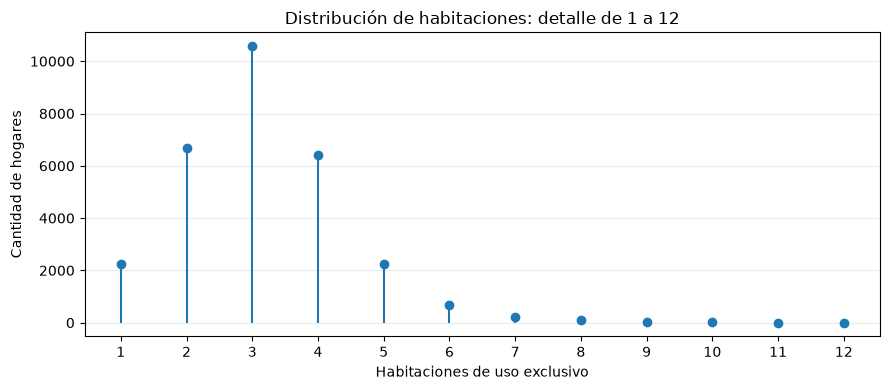

Frecuencias de los valores más altos (sin modificar registros):


,Habitaciones,Hogares,% de válidos
0,92,1,0.003
1,33,1,0.003
2,16,1,0.003
3,12,4,0.014
4,11,5,0.017
5,10,14,0.048
6,9,28,0.096
7,8,89,0.305


Registros inconsistentes: 50
Ejemplos de inconsistencias:


,id,bhho02,bhcv02
27709,1150757060,92,2
17346,1840402661,33,3
7829,948363767,6,5
11482,417950443,6,4
3535,2101373153,6,3
7510,620325690,5,4
17139,1173600307,5,4
1398,28397916,5,4
3514,2075312299,5,4
25131,1979427399,5,3


,Observaciones válidas,Nulos,Mediana,Media,P95,P99,Mínimo,Máximo
0,29224,0,18000.0,22446.65,59000.0,90000.0,0.0,420000.0


Registros con monto igual a 0: 289
Registros que superan $300.000 (máximo del manual): 9
Ingresos positivos que son múltiplos de $1.000: 93.04%
Ingresos positivos que son múltiplos de $5.000: 51.08%
Montos positivos más frecuentes:


,Monto ($),Registros,% entre montos positivos
0,20000,2608,9.01
1,15000,2157,7.45
2,30000,1860,6.43
3,10000,1510,5.22
4,25000,1481,5.12
5,8000,1286,4.44
6,12000,1222,4.22
7,40000,1039,3.59
8,18000,1037,3.58
9,16000,902,3.12


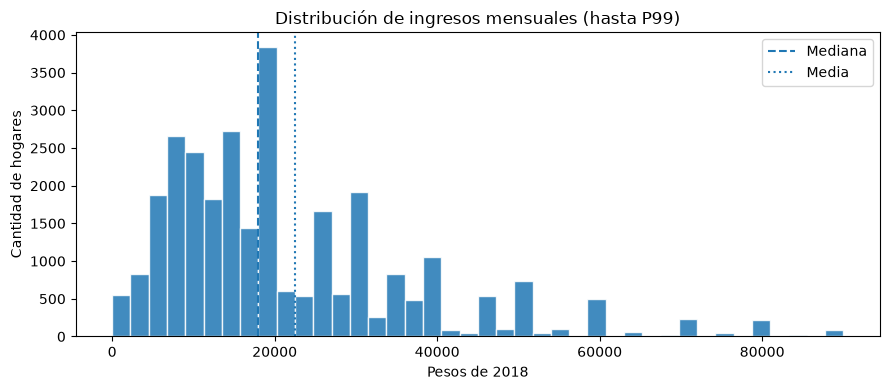

Visualización restringida a valores ≤ P99 ($90,000); el máximo total de $420,000 sigue incluido en las estadísticas.
Registros con código 99 (Ns/Nc): 3186
Registros originalmente vacíos: 16641


,Observaciones válidas,Nulos,Mediana,Media,P95,P99,Mínimo,Máximo
0,20319,8905,180.0,327.64,1200.0,2400.0,10.0,5040.0


Umbrales de inspección (no son criterios de invalidación):


,Valores mayores que,Registros,% de observaciones válidas
0,840,1280,6.30
1,1680,469,2.31
2,3360,30,0.15


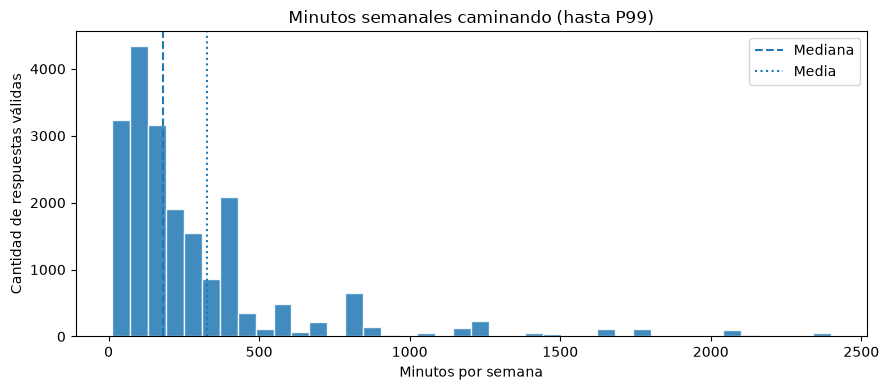

Valores mostrados hasta P99 = 2400.0 minutos/semana; máximo completo = 5040.


,Observaciones válidas,Nulos,Mediana,Media,P95,P99,Mínimo,Máximo
0,1364,27860,4.3,8.23,24.85,47.68,0.3,90.0


Límite exploratorio superior (Q3 + 1,5·RIQ): 23.25 tragos
Registros por encima del límite: 148
Frecuencia de cantidades particularmente altas:


,Valores mayores que,Registros,% de observaciones válidas
0,20,152,11.14
1,30,53,3.89
2,50,7,0.51


/tmp/ipykernel_282205/1109143285.py:182: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(tragos, vert=False, showfliers=True)


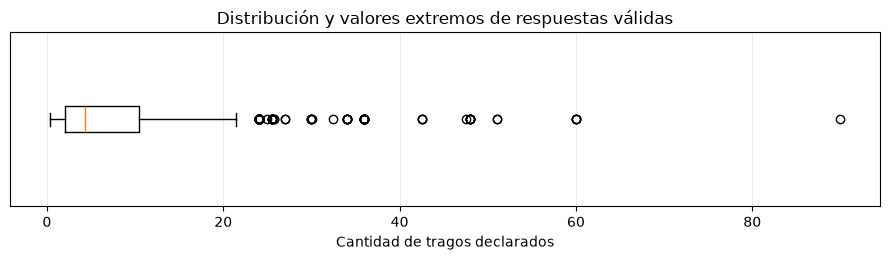

El gráfico utiliza 1364 respuestas observadas de 29224 registros totales.


,Observaciones válidas,Nulos,Mediana,Media,P95,P99,Mínimo,Máximo
0,26995,2229,26.53,27.3,37.02,43.51,10.38,66.67


Conteos exploratorios para inspeccionar ambas colas (no son diagnósticos):


,Condición,Registros
0,IMC < 15,14
1,IMC > 50,61
2,IMC < P1,266
3,IMC > P99,270


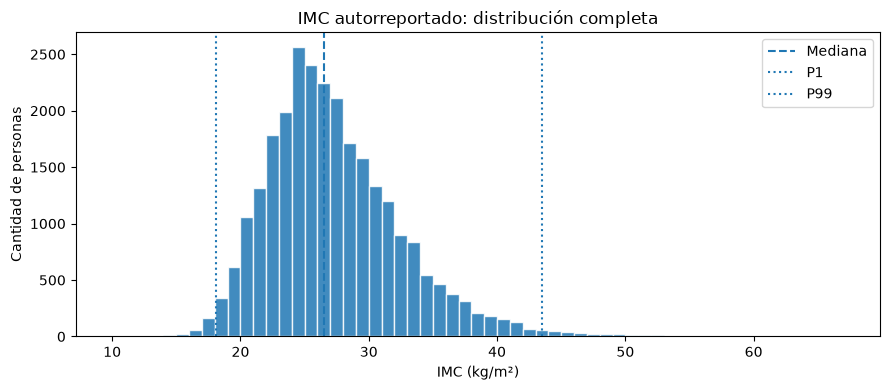

Percentiles extremos: P1 = 18.07; P99 = 43.51.


In [6]:
df_exploracion = df_enfr_limpio  # Usamos los datos tratados en el apartado anterior.

# Funciones comunes para consultar las variables sin repetir cálculos.
def serie_numerica(nombre):
    return pd.to_numeric(df_exploracion[nombre], errors='coerce').dropna()


def resumen_univariado(s):
    return pd.DataFrame([{
        'Observaciones válidas': len(s),
        'Nulos': int(len(df_exploracion) - len(s)),
        'Mediana': round(float(s.median()), 2),
        'Media': round(float(s.mean()), 2),
        'P95': round(float(s.quantile(0.95)), 2),
        'P99': round(float(s.quantile(0.99)), 2),
        'Mínimo': round(float(s.min()), 2),
        'Máximo': round(float(s.max()), 2),
    }])


def tabla_umbral_superior(s, umbrales):
    return pd.DataFrame([{
        'Valores mayores que': umbral,
        'Registros': int(s.gt(umbral).sum()),
        '% de observaciones válidas': round(100 * s.gt(umbral).mean(), 2),
    } for umbral in umbrales])

# Habitaciones del hogar: distribución y valores más altos.
habitaciones = serie_numerica('bhho02')
display(resumen_univariado(habitaciones))

q1, q3 = habitaciones.quantile([0.25, 0.75])
limite_iqr = q3 + 1.5 * (q3 - q1)
print(
    f'Límite superior exploratorio (Q3 + 1,5·RIQ): '
    f'{limite_iqr:.2f} habitaciones'
)
print(f'Registros por encima de ese límite: {(habitaciones > limite_iqr).sum()}')
print(f'Registros con más de 12 habitaciones: {(habitaciones > 12).sum()}')

frecuencias = habitaciones.value_counts().sort_index()
frecuencia_central = frecuencias.reindex(range(1, 13), fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.stem(frecuencia_central.index, frecuencia_central.values, basefmt=' ')
ax.set(
    xlabel='Habitaciones de uso exclusivo',
    ylabel='Cantidad de hogares',
    title='Distribución de habitaciones: detalle de 1 a 12',
)
ax.set_xticks(range(1, 13))
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print('Frecuencias de los valores más altos (sin modificar registros):')
cola_habitaciones = frecuencias.sort_index(ascending=False).head(8)
display(
    pd.DataFrame({
        'Habitaciones': cola_habitaciones.index,
        'Hogares': cola_habitaciones.values,
        '% de válidos': (100 * cola_habitaciones.values / len(habitaciones)).round(3),
    }).reset_index(drop=True)
)

# Comparamos las habitaciones del hogar con las de la vivienda.
comparacion_habitaciones = df_exploracion[
    ['id', 'bhho02', 'bhcv02']
].dropna()

inconsistencias = comparacion_habitaciones[
    comparacion_habitaciones['bhho02'] > comparacion_habitaciones['bhcv02']
]

print(f"Registros inconsistentes: {len(inconsistencias)}")
print("Ejemplos de inconsistencias:")

display(
    inconsistencias.sort_values('bhho02', ascending=False).head(10)
)

# Ingresos del hogar: montos informados y valores frecuentes.
ingresos = serie_numerica('bhih01')
display(resumen_univariado(ingresos))

positivos = ingresos[ingresos > 0]
print(f'Registros con monto igual a 0: {int(ingresos.eq(0).sum())}')
print(
    f'Registros que superan $300.000 (máximo del manual): '
    f'{int(ingresos.gt(300000).sum())}'
)
print(
    f'Ingresos positivos que son múltiplos de $1.000: '
    f'{100 * positivos.mod(1000).eq(0).mean():.2f}%'
)
print(
    f'Ingresos positivos que son múltiplos de $5.000: '
    f'{100 * positivos.mod(5000).eq(0).mean():.2f}%'
)

print('Montos positivos más frecuentes:')
montos_frecuentes = positivos.value_counts().head(10)
display(
    pd.DataFrame({
        'Monto ($)': montos_frecuentes.index,
        'Registros': montos_frecuentes.values,
        '% entre montos positivos': (100 * montos_frecuentes.values / len(positivos)).round(2),
    }).reset_index(drop=True)
)

# Limitamos el histograma a P99 para que los valores altos no oculten el resto.
limite_ingresos = float(ingresos.quantile(0.99))
ingresos_vis = ingresos[ingresos <= limite_ingresos]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ingresos_vis, bins=40, edgecolor='white', alpha=0.85)
ax.axvline(ingresos.median(), linestyle='--', label='Mediana')
ax.axvline(ingresos.mean(), linestyle=':', label='Media')
ax.set(
    title='Distribución de ingresos mensuales (hasta P99)',
    xlabel='Pesos de 2018',
    ylabel='Cantidad de hogares',
)
ax.legend()
plt.tight_layout()
plt.show()
print(
    f'Visualización restringida a valores ≤ P99 (${limite_ingresos:,.0f}); '
    f'el máximo total de ${ingresos.max():,.0f} sigue incluido en las estadísticas.'
)

# Revisamos los códigos originales antes de su tratamiento.
rango_original = raw_dataset['rango_ingreso']

codigos_99 = rango_original.eq(99).sum()
valores_vacios = rango_original.isna().sum()

print(f"Registros con código 99 (Ns/Nc): {codigos_99}")
print(f"Registros originalmente vacíos: {valores_vacios}")

# Caminata: minutos semanales declarados.
caminata = serie_numerica('biaf06_m')
display(resumen_univariado(caminata))

print('Umbrales de inspección (no son criterios de invalidación):')
display(tabla_umbral_superior(caminata, [840, 1680, 3360]))

# El recorte a P99 se aplica solo al gráfico, no a los cálculos.
limite_caminata = float(caminata.quantile(0.99))
caminata_vis = caminata[caminata <= limite_caminata]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(caminata_vis, bins=40, edgecolor='white', alpha=0.85)
ax.axvline(caminata.median(), linestyle='--', label='Mediana')
ax.axvline(caminata.mean(), linestyle=':', label='Media')
ax.set(
    title='Minutos semanales caminando (hasta P99)',
    xlabel='Minutos por semana',
    ylabel='Cantidad de respuestas válidas',
)
ax.legend()
plt.tight_layout()
plt.show()
print(
    f'Valores mostrados hasta P99 = {limite_caminata:.1f} minutos/semana; '
    f'máximo completo = {caminata.max():.0f}.'
)

# Consumo de alcohol: cantidades declaradas y valores extremos.
tragos = serie_numerica('bica05_03_b')
display(resumen_univariado(tragos))

q1, q3 = tragos.quantile([0.25, 0.75])
limite_tragos = q3 + 1.5 * (q3 - q1)
print(
    f'Límite exploratorio superior (Q3 + 1,5·RIQ): '
    f'{limite_tragos:.2f} tragos'
)
print(f'Registros por encima del límite: {int(tragos.gt(limite_tragos).sum())}')
print('Frecuencia de cantidades particularmente altas:')
display(tabla_umbral_superior(tragos, [20, 30, 50]))

fig, ax = plt.subplots(figsize=(9, 2.7))
ax.boxplot(tragos, vert=False, showfliers=True)
ax.set(
    xlabel='Cantidad de tragos declarados',
    title='Distribución y valores extremos de respuestas válidas',
)
ax.set_yticks([])
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()
print(
    f'El gráfico utiliza {len(tragos)} respuestas observadas '
    f'de {len(df_exploracion)} registros totales.'
)

# IMC autorreportado: distribución completa y observaciones en ambas colas.
imc_autorreportado = serie_numerica('imc')
display(resumen_univariado(imc_autorreportado))

q01, q99 = imc_autorreportado.quantile([0.01, 0.99])
print('Conteos exploratorios para inspeccionar ambas colas (no son diagnósticos):')
display(pd.DataFrame([
    {'Condición': 'IMC < 15', 'Registros': int(imc_autorreportado.lt(15).sum())},
    {'Condición': 'IMC > 50', 'Registros': int(imc_autorreportado.gt(50).sum())},
    {'Condición': 'IMC < P1', 'Registros': int(imc_autorreportado.lt(q01).sum())},
    {'Condición': 'IMC > P99', 'Registros': int(imc_autorreportado.gt(q99).sum())},
]))

bins_imc = np.arange(
    np.floor(imc_autorreportado.min()),
    np.ceil(imc_autorreportado.max()) + 1,
    1,
)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(imc_autorreportado, bins=bins_imc, edgecolor='white', alpha=0.85)
ax.axvline(imc_autorreportado.median(), linestyle='--', label='Mediana')
ax.axvline(q01, linestyle=':', label='P1')
ax.axvline(q99, linestyle=':', label='P99')
ax.set(
    title='IMC autorreportado: distribución completa',
    xlabel='IMC (kg/m²)',
    ylabel='Cantidad de personas',
)
ax.legend()
plt.tight_layout()
plt.show()
print(f'Percentiles extremos: P1 = {q01:.2f}; P99 = {q99:.2f}.')


# 2. Selección y preparación de los datos
## 2.1. Selección de variables y recorte de la base
De las 287 variables de la ENFR 2018 seleccionamos las que vamos a utilizar en las hipótesis: edad, sexo, consumo de frutas y verduras, actividad física y mediciones de peso, talla, cintura, presión arterial y glucemia. También conservamos los identificadores, la información de las submuestras y los factores de expansión de los tres pasos de la encuesta.

El recorte se realiza a partir de df_enfr_limpio, que contiene el tratamiento inicial de códigos especiales del punto 1. Renombramos algunas columnas para trabajar con nombres más fáciles de identificar, sin modificar la base original.

In [7]:
# Seleccionamos las columnas que se utilizarán en las hipótesis.
columnas_seleccionadas = [
    'id', 'submuestra', 'localidades_150',
    'wf1p', 'wf2p', 'wf3p',
    'bhch03', 'bhch04', 'promedio_fv_diario',
    'bima10', 'bima07', 'imc_bima', 'nivel_actividad_fisica',
    'promedio_sistolica', 'promedio_diastolica',
    'bima13', 'bimq05'
]

df_recorte = df_enfr_limpio[columnas_seleccionadas].copy()

# Usamos nombres más claros para trabajar con las variables seleccionadas.
nuevos_nombres = {
    'id': 'id_encuestado',
    'bhch03': 'sexo',
    'bhch04': 'edad',
    'promedio_fv_diario': 'consumo_diario_fv',
    'bima10': 'peso_kg',
    'bima07': 'talla_cm',
    'imc_bima': 'imc',
    'nivel_actividad_fisica': 'actividad_fisica',
    'promedio_sistolica': 'presion_sistolica',
    'promedio_diastolica': 'presion_diastolica',
    'bima13': 'cintura_cm',
    'bimq05': 'glucemia_mg_dl'
}

df_recorte.rename(columns=nuevos_nombres, inplace=True)

print(f'La base original tenía {raw_dataset.shape[1]} columnas.')
print(
    f'El recorte de interés cuenta con {df_recorte.shape[0]} registros '
    f'y {df_recorte.shape[1]} variables.\n'
)


La base original tenía 287 columnas.
El recorte de interés cuenta con 29224 registros y 17 variables.



/tmp/ipykernel_282205/4226136026.py:29: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_recorte.rename(columns=nuevos_nombres, inplace=True)


### 2.1.1. Tipos de variables seleccionadas
Aunque muchas columnas estén almacenadas como números, no todas son cuantitativas. Por ejemplo, actividad_fisica representa tres categorías ordenadas (alta, media y baja), mientras que submuestra y localidades_150 identifican categorías binarias.

La edad se registra en años cumplidos; el consumo, el peso, la talla, el IMC, las presiones, la cintura y la glucemia son variables cuantitativas. id_encuestado identifica cada registro y wf1p, wf2p y wf3p son los factores de expansión correspondientes a los tres pasos de la encuesta.

## 2.2. Exploración de las variables seleccionadas
Revisamos los valores faltantes, las medidas descriptivas y los posibles valores atípicos de las variables elegidas. Después observamos algunas distribuciones para reconocer sus concentraciones y extremos. Esta etapa es descriptiva: todavía no se eliminan ni se modifican registros.

### 2.2.1. Valores faltantes, medidas descriptivas y posibles atípicos
Presentamos el porcentaje de nulos de todas las variables seleccionadas y las estadísticas principales de las cuantitativas. Luego usamos el rango intercuartílico (IQR) para señalar posibles valores atípicos, contando solo las observaciones válidas.

In [8]:
variables_numericas = [
    'edad', 'consumo_diario_fv', 'peso_kg', 'talla_cm',
    'imc', 'presion_sistolica', 'presion_diastolica',
    'cintura_cm', 'glucemia_mg_dl'
]

# Primero revisamos la disponibilidad de todas las columnas del recorte.
print('--- VALORES NULOS ---')
resumen_nulos = pd.DataFrame({
    'Nulos': df_recorte.isna().sum(),
    '% Nulos': (df_recorte.isna().mean() * 100).round(2)
})
display(resumen_nulos)

# Las medidas descriptivas se calculan solo sobre las variables cuantitativas.
print('\n--- RESUMEN ESTADÍSTICO ---')
display(df_recorte[variables_numericas].describe().T.round(2))

# El criterio IQR señala posibles atípicos; no implica que sean errores.
print('\n--- POSIBLES OUTLIERS (IQR) ---')
resultados_iqr = []

for columna in variables_numericas:
    s = df_recorte[columna].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr

    atipicos = ((s < inferior) | (s > superior)).sum()

    resultados_iqr.append({
        'Variable': columna,
        'Límite inferior': round(inferior, 2),
        'Límite superior': round(superior, 2),
        'Outliers': atipicos,
        '% sobre válidos': round(atipicos / len(s) * 100, 2)
    })

display(pd.DataFrame(resultados_iqr))


--- VALORES NULOS ---


,Nulos,% Nulos
id_encuestado,0,0.00
submuestra,0,0.00
localidades_150,0,0.00
wf1p,0,0.00
wf2p,0,0.00
wf3p,0,0.00
sexo,0,0.00
edad,0,0.00
consumo_diario_fv,753,2.58
peso_kg,12799,43.80



--- RESUMEN ESTADÍSTICO ---


,count,mean,std,min,25%,50%,75%,max
edad,29224.0,46.49,18.05,18.00,32.00,44.00,61.00,104.00
consumo_diario_fv,28471.0,2.07,1.71,0.00,1.00,1.64,2.71,18.00
peso_kg,16425.0,76.14,17.42,33.00,64.00,74.00,86.00,200.00
talla_cm,16491.0,164.18,9.71,114.00,157.00,164.00,171.00,201.00
imc,16410.0,28.22,5.92,14.15,24.01,27.41,31.55,86.57
presion_sistolica,16227.0,130.65,20.89,67.00,116.00,127.50,141.50,249.00
presion_diastolica,16227.0,84.17,12.54,31.00,75.50,83.50,91.50,167.50
cintura_cm,16312.0,91.94,15.95,40.00,81.00,92.00,102.00,230.00
glucemia_mg_dl,5188.0,80.87,30.90,20.00,65.00,79.00,92.00,382.00



--- POSIBLES OUTLIERS (IQR) ---


,Variable,Límite inferior,Límite superior,Outliers,% sobre válidos
0,edad,-11.50,104.50,0,0.00
1,consumo_diario_fv,-1.56,5.28,1206,4.24
2,peso_kg,31.00,119.00,301,1.83
3,talla_cm,136.00,192.00,41,0.25
4,imc,12.70,42.86,343,2.09
5,presion_sistolica,77.75,179.75,456,2.81
6,presion_diastolica,51.50,115.50,301,1.85
7,cintura_cm,49.50,133.50,170,1.04
8,glucemia_mg_dl,24.50,132.50,251,4.84


### 2.2.2. Distribución de variables cuantitativas
Mostramos histogramas de seis variables con una línea que indica la mediana. Para el consumo de frutas y verduras también marcamos las cinco porciones diarias como referencia.

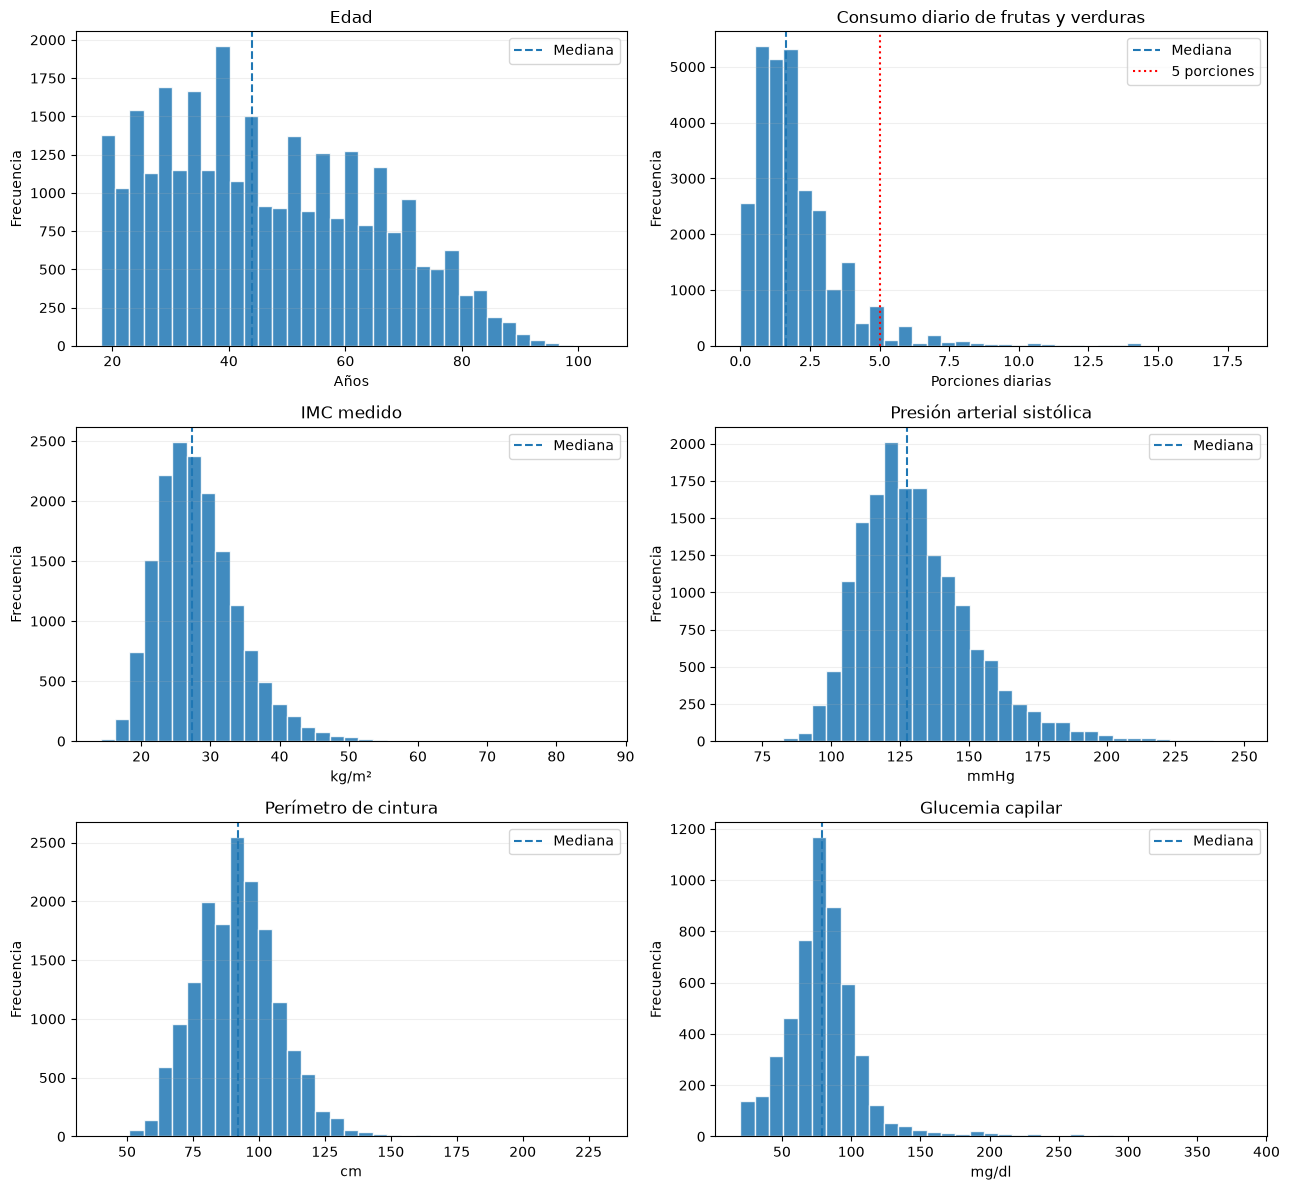

In [9]:
# Mostramos algunas variables cuantitativas con un formato común.
graficos = [
    ('edad', 'Edad', 'Años'),
    ('consumo_diario_fv', 'Consumo diario de frutas y verduras', 'Porciones diarias'),
    ('imc', 'IMC medido', 'kg/m²'),
    ('presion_sistolica', 'Presión arterial sistólica', 'mmHg'),
    ('cintura_cm', 'Perímetro de cintura', 'cm'),
    ('glucemia_mg_dl', 'Glucemia capilar', 'mg/dl')
]

fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for ax, (columna, titulo, unidad) in zip(axes.flat, graficos):
    valores = df_recorte[columna].dropna()

    ax.hist(valores, bins=35, edgecolor='white', alpha=0.85)
    ax.axvline(valores.median(), linestyle='--', label='Mediana')

    # En consumo de frutas y verduras marcamos la referencia de cinco porciones.
    if columna == 'consumo_diario_fv':
        ax.axvline(5, color='red', linestyle=':', label='5 porciones')

    ax.set_title(titulo)
    ax.set_xlabel(unidad)
    ax.set_ylabel('Frecuencia')
    ax.legend()
    ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()


### 2.2.3. Distribución de los niveles de actividad física
Mostramos la frecuencia y el porcentaje de los niveles alto, medio y bajo de actividad física, sin incluir respuestas faltantes.

,Frecuencia,Porcentaje sobre válidos
actividad_fisica,,
Alta,4859,16.77
Media,10347,35.72
Baja,13764,47.51


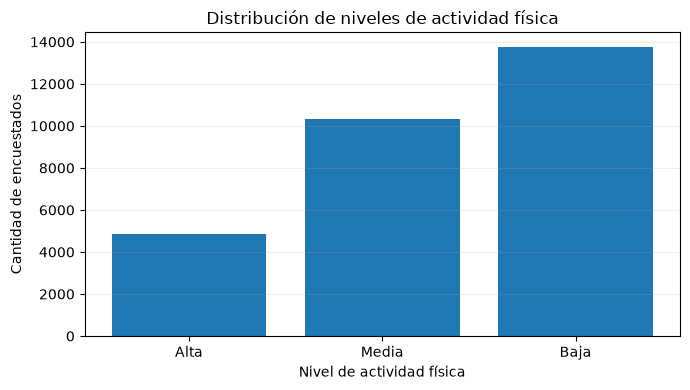

In [10]:
# Los códigos 1, 2 y 3 representan actividad física alta, media y baja.
mapa_af = {1: 'Alta', 2: 'Media', 3: 'Baja'}

frecuencias_af = (
    df_recorte['actividad_fisica']
    .map(mapa_af)
    .value_counts()
    .reindex(['Alta', 'Media', 'Baja'], fill_value=0)
)

display(pd.DataFrame({
    'Frecuencia': frecuencias_af,
    'Porcentaje sobre válidos': (
        frecuencias_af / frecuencias_af.sum() * 100
    ).round(2)
}))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(frecuencias_af.index, frecuencias_af.values)

ax.set_title('Distribución de niveles de actividad física')
ax.set_xlabel('Nivel de actividad física')
ax.set_ylabel('Cantidad de encuestados')
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()


## 2.3. Revisión de calidad y preparación de los datos
Después del tratamiento inicial de códigos especiales del punto 1, revisamos la disponibilidad de mediciones según el paso de la encuesta, buscamos posibles inconsistencias y preparamos una muestra específica para cada hipótesis.

### 2.3.1. Organización por pasos y tratamiento de valores faltantes
No todas las personas participaron de los tres pasos de la ENFR, por lo que algunas mediciones no están disponibles para todos los registros. En lugar de eliminar todas las filas que tengan algún valor faltante, separamos los registros según el factor de expansión válido de cada paso.

En la sección 2.3.3 seleccionaremos, para cada hipótesis, únicamente las observaciones que tengan completas las variables necesarias.

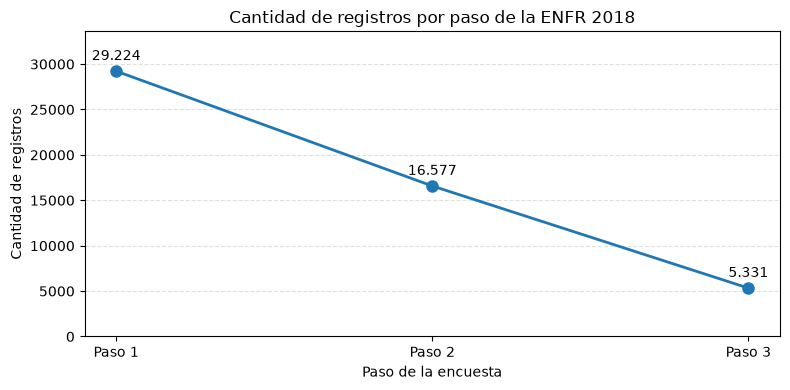

In [11]:
# Cada paso conserva los registros que tienen un factor de expansión positivo.
df_paso1 = df_recorte[df_recorte['wf1p'] > 0].copy()
df_paso2 = df_recorte[df_recorte['wf2p'] > 0].copy()
df_paso3 = df_recorte[df_recorte['wf3p'] > 0].copy()

resumen_etapas = pd.DataFrame({
    'Etapa': ['Paso 1', 'Paso 2', 'Paso 3'],
    'Registros': [len(df_paso1), len(df_paso2), len(df_paso3)]
})

plt.figure(figsize=(8, 4))
plt.plot(
    resumen_etapas['Etapa'],
    resumen_etapas['Registros'],
    marker='o',
    linewidth=2,
    markersize=8
)

for i, cantidad in enumerate(resumen_etapas['Registros']):
    plt.annotate(
        f'{cantidad:,}'.replace(',', '.'),
        (i, cantidad),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center'
    )

plt.title('Cantidad de registros por paso de la ENFR 2018')
plt.xlabel('Paso de la encuesta')
plt.ylabel('Cantidad de registros')
plt.ylim(0, resumen_etapas['Registros'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### 2.3.2. Controles de consistencia y revisión de valores extremos
Primero comprobamos identificadores duplicados, edades fuera de la población objetivo, códigos inesperados de actividad física y mediciones no positivas. También revisamos la relación entre presión sistólica y diastólica, y comparamos el IMC registrado con el que se obtiene a partir del peso y la talla.

Después señalamos valores que quedan fuera de ciertos rangos orientativos y mostramos ejemplos junto con sus otras mediciones. Estos rangos no son límites oficiales de validez del INDEC y se utilizan únicamente para localizar casos que convendría revisar, no para excluirlos automáticamente.

In [12]:
# Comprobamos identificadores, códigos fuera de rango y valores no positivos.
controles = {
    'Identificadores duplicados (filas involucradas)': (
        df_recorte['id_encuestado'].duplicated(keep=False).sum()
    ),
    'Edad inferior a 18 años': df_recorte['edad'].lt(18).sum(),
    'Actividad física fuera de 1, 2 y 3': (
        df_recorte['actividad_fisica'].notna()
        & ~df_recorte['actividad_fisica'].isin([1, 2, 3])
    ).sum(),
    'Consumo de frutas y verduras negativo': df_recorte['consumo_diario_fv'].lt(0).sum(),
}

for variable in [
    'peso_kg', 'talla_cm', 'imc', 'presion_sistolica',
    'presion_diastolica', 'cintura_cm', 'glucemia_mg_dl'
]:
    controles[f'{variable}: valor no positivo'] = df_recorte[variable].le(0).sum()

# Cruzamos mediciones que deberían ser coherentes entre sí.
pas = df_recorte['presion_sistolica']
pad = df_recorte['presion_diastolica']
controles['Presión sistólica <= diastólica'] = (pas <= pad).sum()
controles['Solo una de las dos presiones está informada'] = (
    pas.isna() != pad.isna()
).sum()

datos_imc = df_recorte[['peso_kg', 'talla_cm', 'imc']].dropna()
datos_imc = datos_imc[(datos_imc['peso_kg'] > 0) & (datos_imc['talla_cm'] > 0)]
imc_recalculado = datos_imc['peso_kg'] / (datos_imc['talla_cm'] / 100) ** 2
diferencia_imc = (datos_imc['imc'] - imc_recalculado).abs()
controles['IMC: diferencia mayor a 0.05 respecto del cálculo'] = (
    diferencia_imc.gt(0.05).sum()
)

print('CONTROLES DE CONSISTENCIA')
display(pd.DataFrame({
    'Control': list(controles),
    'Registros detectados': [int(v) for v in controles.values()]
}))
print(
    f'IMC comparados: {len(diferencia_imc)} | '
    f'diferencia mediana: {diferencia_imc.median():.3f} | '
    f'diferencia máxima: {diferencia_imc.max():.3f}'
)

# Estos rangos solo permiten localizar observaciones para revisar.
rangos_revision = {
    'talla_cm': (120, 220),
    'peso_kg': (30, 220),
    'imc': (12, 75),
    'presion_sistolica': (60, 240),
    'presion_diastolica': (40, 140),
    'cintura_cm': (40, 200),
    'glucemia_mg_dl': (40, 300),
    'consumo_diario_fv': (0, 10),
}

resumen_alertas = []
casos_ejemplo = []
indices_alerta = set()
variables_contexto = [
    'edad', 'peso_kg', 'talla_cm', 'imc', 'presion_sistolica',
    'presion_diastolica', 'cintura_cm', 'glucemia_mg_dl', 'consumo_diario_fv'
]

for variable, (minimo, maximo) in rangos_revision.items():
    serie = df_recorte[variable]
    bajos = serie.lt(minimo)
    altos = serie.gt(maximo)
    indices_alerta.update(df_recorte.index[bajos | altos].tolist())

    resumen_alertas.append({
        'Variable': variable,
        'Criterio de revisión': f'< {minimo} o > {maximo}',
        'Por debajo': int(bajos.sum()),
        'Por encima': int(altos.sum()),
        'Total señalado': int((bajos | altos).sum()),
        'Mínimo observado': serie.min(),
        'Máximo observado': serie.max(),
    })

    # Elegimos un ejemplo de cada extremo y conservamos el resto de sus mediciones.
    for mascara, tipo in [(bajos, 'Mínimo'), (altos, 'Máximo')]:
        if mascara.any():
            indice = (
                serie[mascara].idxmin()
                if tipo == 'Mínimo'
                else serie[mascara].idxmax()
            )
            fila = df_recorte.loc[indice, ['id_encuestado'] + variables_contexto]
            casos_ejemplo.append({
                'Alerta': f'{variable} — {tipo.lower()}',
                'Valor que activó la alerta': serie.loc[indice],
                'id_encuestado': fila['id_encuestado'],
                **{v: fila[v] for v in variables_contexto}
            })

print('\nALERTAS EXPLORATORIAS (NO SON EXCLUSIONES)')
display(pd.DataFrame(resumen_alertas))
print(f'Registros distintos con al menos una alerta: {len(indices_alerta)}')

print('\nCASOS EXTREMOS PARA REVISAR CON SUS OTRAS MEDICIONES')
if casos_ejemplo:
    display(pd.DataFrame(casos_ejemplo).round(2))
else:
    print('No se detectaron casos bajo estos criterios orientativos.')


CONTROLES DE CONSISTENCIA


,Control,Registros detectados
0,Identificadores duplicados (filas involucradas),0
1,Edad inferior a 18 años,0
2,"Actividad física fuera de 1, 2 y 3",0
3,Consumo de frutas y verduras negativo,0
4,peso_kg: valor no positivo,0
5,talla_cm: valor no positivo,0
6,imc: valor no positivo,0
7,presion_sistolica: valor no positivo,0
8,presion_diastolica: valor no positivo,0
9,cintura_cm: valor no positivo,0


IMC comparados: 16410 | diferencia mediana: 0.002 | diferencia máxima: 0.005

ALERTAS EXPLORATORIAS (NO SON EXCLUSIONES)


,Variable,Criterio de revisión,Por debajo,Por encima,Total señalado,Mínimo observado,Máximo observado
0,talla_cm,< 120 o > 220,1,0,1,114.00,201.00
1,peso_kg,< 30 o > 220,0,0,0,33.00,200.00
2,imc,< 12 o > 75,0,1,1,14.15,86.57
3,presion_sistolica,< 60 o > 240,0,6,6,67.00,249.00
4,presion_diastolica,< 40 o > 140,3,11,14,31.00,167.50
5,cintura_cm,< 40 o > 200,0,9,9,40.00,230.00
6,glucemia_mg_dl,< 40 o > 300,283,4,287,20.00,382.00
7,consumo_diario_fv,< 0 o > 10,0,183,183,0.00,18.00


Registros distintos con al menos una alerta: 499

CASOS EXTREMOS PARA REVISAR CON SUS OTRAS MEDICIONES


,Alerta,Valor que activó la alerta,id_encuestado,edad,peso_kg,talla_cm,imc,presion_sistolica,presion_diastolica,cintura_cm,glucemia_mg_dl,consumo_diario_fv
0,talla_cm — mínimo,114.00,1.805306e+09,81.0,56.0,114.0,43.09,164.5,78.0,101.0,NaN,1.43
1,imc — máximo,86.57,2.021477e+09,68.0,200.0,152.0,86.57,160.5,81.0,186.0,NaN,2.86
2,presion_sistolica — máximo,249.00,2.227627e+08,46.0,134.0,182.0,40.45,249.0,140.0,121.0,NaN,2.57
3,presion_diastolica — mínimo,31.00,1.597543e+09,48.0,60.0,165.0,22.04,125.0,31.0,80.0,NaN,1.43
4,presion_diastolica — máximo,167.50,8.311437e+08,58.0,115.0,149.0,51.80,242.5,167.5,115.0,NaN,1.29
5,cintura_cm — máximo,230.00,1.847548e+09,44.0,119.0,167.0,42.67,146.5,102.5,230.0,NaN,2.43
6,glucemia_mg_dl — mínimo,20.00,1.121484e+09,41.0,52.0,162.0,19.81,91.5,66.5,62.0,20.0,3.00
7,glucemia_mg_dl — máximo,382.00,1.930465e+09,68.0,65.0,153.0,27.77,155.0,90.0,97.0,382.0,2.43
8,consumo_diario_fv — máximo,18.00,1.273724e+09,62.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.00


Los controles permiten distinguir valores poco frecuentes de posibles inconsistencias entre respuestas o mediciones. Por ahora conservamos todos los registros: esta sección identifica casos para revisar, pero no aplica correcciones ni elimina valores extremos.

### 2.3.3. Preparación de las muestras para las hipótesis y controles de integridad
Construimos una muestra para cada una de las seis hipótesis, tomando los registros del paso correspondiente y descartando únicamente los que no tienen alguna de las variables necesarias para ese análisis. Conservamos también el factor de expansión que se utilizará en la validación estadística.

Para la hipótesis 2 seleccionamos solo los niveles alto y bajo de actividad física; el nivel medio se excluye por el planteo de esa comparación, no por ser un dato inválido. El resumen distingue las exclusiones por valores faltantes de las exclusiones por grupo. Por último, comprobamos que las muestras tengan identificadores únicos, factores positivos y variables completas.

In [13]:
# Dejamos completas únicamente las variables que requiere cada hipótesis.
def seleccionar_muestra(base, variables, factor, niveles=None):
    columnas = ['id_encuestado'] + variables + [factor]
    muestra = base[columnas].dropna(subset=variables).copy()
    if niveles is not None:
        muestra = muestra[muestra['actividad_fisica'].isin(niveles)].copy()
    return muestra


# Separamos las muestras según las variables y el paso de la encuesta.
base_h1 = df_paso2[df_paso2['sexo'] == 2].copy()

df_h1 = seleccionar_muestra(
    base_h1, ['cintura_cm'], 'wf2p'
)
df_h1['cintura_elevada'] = (df_h1['cintura_cm'] >= 88).astype(int)

df_h2 = seleccionar_muestra(
    df_paso2, ['presion_sistolica', 'actividad_fisica'], 'wf2p', niveles=[1, 3]
)
df_h3 = seleccionar_muestra(
    df_paso2,
    ['imc', 'consumo_diario_fv', 'edad', 'actividad_fisica'],
    'wf2p',
    niveles=[1, 2, 3]
)
df_h4 = seleccionar_muestra(df_paso1, ['consumo_diario_fv'], 'wf1p')
df_h5 = seleccionar_muestra(
    df_paso2, ['imc', 'actividad_fisica'], 'wf2p', niveles=[1, 2, 3]
)
df_h6 = seleccionar_muestra(
    df_paso3,
    ['imc', 'presion_sistolica', 'cintura_cm', 'edad', 'glucemia_mg_dl'],
    'wf3p'
)

# Guardamos cada muestra junto con la base de origen y sus variables necesarias.
muestras = {
    'H1 - Cintura': (df_h1, base_h1, ['cintura_cm']),
    'H2 - Presión y actividad': (
        df_h2, df_paso2, ['presion_sistolica', 'actividad_fisica']
    ),
    'H3 - Alimentación e IMC': (
        df_h3,
        df_paso2,
        ['imc', 'consumo_diario_fv', 'edad', 'actividad_fisica']
    ),
    'H4 - Frutas y verduras': (df_h4, df_paso1, ['consumo_diario_fv']),
    'H5 - IMC y actividad': (df_h5, df_paso2, ['imc', 'actividad_fisica']),
    'H6 - Modelo multivariado': (
        df_h6, df_paso3,
        ['imc', 'presion_sistolica', 'cintura_cm', 'edad', 'glucemia_mg_dl']
    )
}

# Distinguimos los registros perdidos por nulos de los excluidos por grupo.
resumen_muestras = []
for nombre, (muestra, base, variables) in muestras.items():
    completos = base.dropna(subset=variables)
    excluidos_faltantes = len(base) - len(completos)
    excluidos_grupo = len(completos) - len(muestra)
    resumen_muestras.append({
        'Hipótesis': nombre,
        'Registros del paso': len(base),
        'Excluidos por faltantes': excluidos_faltantes,
        'Excluidos por grupo': excluidos_grupo,
        'Registros válidos': len(muestra),
        '% conservado': round(len(muestra) / len(base) * 100, 2)
    })

display(pd.DataFrame(resumen_muestras))

# Comprobamos que las muestras estén listas para los análisis posteriores.
for nombre, (muestra, _, _) in muestras.items():
    factor = next(c for c in muestra.columns if c in ['wf1p', 'wf2p', 'wf3p'])
    assert muestra['id_encuestado'].is_unique, f'{nombre}: identificadores repetidos'
    assert muestra[factor].gt(0).all(), f'{nombre}: factor no positivo'
    assert muestra.drop(columns=['id_encuestado', factor]).notna().all().all(), (
        f'{nombre}: valores faltantes'
    )

print('Todas las muestras cumplen los controles.')


,Hipótesis,Registros del paso,Excluidos por faltantes,Excluidos por grupo,Registros válidos,% conservado
0,H1 - Cintura,9551,163,0,9388,98.29
1,H2 - Presión y actividad,16577,482,5759,10336,62.35
2,H3 - Alimentación e IMC,16577,739,0,15838,95.54
3,H4 - Frutas y verduras,29224,753,0,28471,97.42
4,H5 - IMC y actividad,16577,295,0,16282,98.22
5,H6 - Modelo multivariado,5331,292,0,5039,94.52


Todas las muestras cumplen los controles.


Al finalizar obtenemos seis muestras, cada una con las variables y los registros necesarios para su hipótesis. Hasta acá mostramos cantidades de registros sin ponderar; los factores de expansión se mantienen para los análisis estadísticos posteriores.

# 3. Planteo de hipótesis
Planteamos tres hipótesis propias a partir de las variables seleccionadas: una univariada, una bivariada y una multivariada. En cada caso presentamos la pregunta de investigación y su formulación estadística. Las pruebas se realizan en el punto 4.

## 3.1. H1 — Perímetro de cintura en mujeres (univariada)
### Planteo
El perímetro de cintura es un indicador de acumulación de grasa abdominal y está relacionado con el riesgo cardiovascular y metabólico. Nos interesa evaluar si más de la mitad de las mujeres adultas alcanza o supera los 88 cm de cintura, umbral utilizado como referencia de riesgo elevado.

### Hipótesis de investigación
Más del 50% de las mujeres adultas de la población urbana argentina de localidades de 5.000 habitantes o más tiene un perímetro de cintura igual o superior a 88 cm.
### Formulación estadística
- H0: p ≤ 0,50
- H1: p > 0,50
Donde p es la proporción poblacional de mujeres con un perímetro de cintura de 88 cm o más.

## 3.2. H2 — Presión sistólica y actividad física (bivariada)
### Planteo
La actividad física está relacionada con la salud cardiovascular. Nos interesa comparar la presión arterial sistólica de las personas con actividad física alta y baja para evaluar si existe una diferencia entre ambos grupos.

### Hipótesis de investigación
Las personas adultas con actividad física baja presentan una presión sistólica media mayor que aquellas con actividad física alta, en la población urbana argentina de localidades de 5.000 habitantes o más.
### Formulación estadística
- H0: μ_baja ≤ μ_alta
- H1: μ_baja > μ_alta
Donde μ_baja y μ_alta representan las medias poblacionales de presión sistólica en cada grupo.

## 3.3. H3 — Consumo de frutas y verduras e IMC (multivariada)
### Planteo
El consumo de frutas y verduras puede relacionarse con el peso corporal, aunque también intervienen la edad y la actividad física. Nos interesa analizar la relación entre el consumo diario y el IMC considerando estas otras variables.

### Hipótesis de investigación
Un mayor consumo diario de frutas y verduras se asocia con un menor IMC en la población adulta urbana argentina de localidades de 5.000 habitantes o más, después de ajustar por edad y nivel de actividad física.
### Formulación estadística
- H0: β_consumo ≥ 0
- H1: β_consumo < 0
Donde β_consumo es el coeficiente del consumo diario de frutas y verduras en una regresión lineal múltiple que incluye la edad y el nivel de actividad física.

# 4. Validación de hipótesis
Validamos las tres hipótesis propias y las tres propuestas por la cátedra. Para cada una presentamos los datos utilizados, las medidas descriptivas y el contraste estadístico correspondiente.

Utilizamos los factores de expansión del paso de la encuesta que corresponde a cada análisis y los 200 pesos replicados del INDEC para estimar la variabilidad muestral. Los resultados y su interpretación se desarrollan en el informe.

## Preparación inicial de los pesos replicados del Paso 2
Descargamos la base de réplicas del INDEC y seleccionamos el identificador de cada registro junto con los 200 ponderadores del Paso 2 (wf2p_rep1 a wf2p_rep200). Estos datos se utilizan en H1, H2, H3 y H5.

In [14]:
url = 'https://www.indec.gob.ar/ftp/cuadros/menusuperior/enfr/base_replicas_enfr2018.zip'
ruta = Path('base_replicas_enfr2018.zip')
if not ruta.exists() and Path('datos/base_replicas_enfr2018.zip').exists():
    ruta = Path('datos/base_replicas_enfr2018.zip')

# Reutilizamos el archivo descargado cuando ya está disponible.
if not ruta.exists():
    with requests.get(url, stream=True, timeout=(20, 180)) as respuesta:
        respuesta.raise_for_status()
        with open(ruta, 'wb') as archivo:
            for bloque in respuesta.iter_content(chunk_size=1024 * 1024):
                archivo.write(bloque)

# Leemos únicamente el identificador y los pesos replicados del Paso 2.
with ZipFile(ruta) as archivo:
    nombres = [
        n for n in archivo.namelist()
        if n.lower().endswith(('.txt', '.csv'))
    ]

    nombre = next(
        (n for n in nombres if 'rep' in n.lower()),
        nombres[0]
    )

    with archivo.open(nombre) as contenido:
        df_replicas = pd.read_csv(
            contenido,
            sep='|',
            usecols=lambda c: (
                c.strip().lower() == 'id' or
                c.strip().lower().startswith('wf2p_rep')
            )
        )

df_replicas.columns = df_replicas.columns.str.strip().str.lower()
df_replicas.rename(columns={'id': 'id_encuestado'}, inplace=True)

columnas_rep = [f"wf2p_rep{i}" for i in range(1, 201)]

# Comprobamos que estén las 200 réplicas y que los identificadores sean únicos.
assert all(c in df_replicas.columns for c in columnas_rep)
assert df_replicas['id_encuestado'].is_unique

print(f"Registros: {len(df_replicas)}")
print(f"Pesos replicados del Paso 2: {len(columnas_rep)}")

Registros: 29224
Pesos replicados del Paso 2: 200


/tmp/ipykernel_282205/1070893471.py:37: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_replicas.rename(columns={'id': 'id_encuestado'}, inplace=True)


## 4.1. H1 — Perímetro de cintura en mujeres
Calculamos la proporción de mujeres con perímetro de cintura de 88 cm o más, tanto en la muestra como aplicando wf2p. Luego utilizamos las réplicas del Paso 2 para obtener el error estándar, el intervalo de confianza y el p-valor del contraste unilateral frente al 50%.

,Grupo,Frecuencia,Porcentaje observado,Porcentaje ponderado
0,Cintura < 88 cm,4445,47.35,51.43
1,Cintura >= 88 cm,4943,52.65,48.57


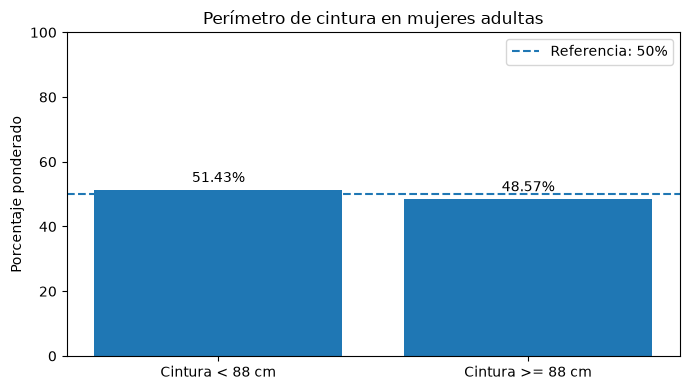


H1 - VALIDACIÓN ESTADÍSTICA
Observaciones válidas: 9388
Proporción observada: 0.5265
Proporción ponderada: 0.4857
Error estándar bootstrap: 0.010859
IC 95%: [0.4644, 0.5070]
CV de la proporción: 2.24%
CV del denominador: 1.76%
Estadístico Z: -1.3147
P-valor unilateral: 0.905696


In [15]:
alpha = 0.05
p0 = 0.50
umbral = 88

# Calculamos la proporción observada y la estimación ponderada.
datos = df_h1.copy()
datos['cintura_elevada'] = (datos['cintura_cm'] >= umbral).astype(int)

n = len(datos)
k = int(datos['cintura_elevada'].sum())

p_observada = k / n
p_ponderada = np.average(
    datos['cintura_elevada'],
    weights=datos['wf2p']
)

tabla = pd.DataFrame({
    'Grupo': ['Cintura < 88 cm', 'Cintura >= 88 cm'],
    'Frecuencia': [n - k, k],
    'Porcentaje observado': [
        (1 - p_observada) * 100,
        p_observada * 100
    ],
    'Porcentaje ponderado': [
        (1 - p_ponderada) * 100,
        p_ponderada * 100
    ]
})

display(tabla.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(tabla['Grupo'], tabla['Porcentaje ponderado'])
ax.axhline(50, linestyle='--', label='Referencia: 50%')
ax.bar_label(barras, fmt='%.2f%%', padding=3)
ax.set_ylim(0, 100)
ax.set_ylabel('Porcentaje ponderado')
ax.set_title('Perímetro de cintura en mujeres adultas')
ax.legend()
plt.tight_layout()
plt.show()

# Unificamos los identificadores antes de incorporar los pesos replicados.
base = df_paso2[
    ['id_encuestado', 'sexo', 'cintura_cm', 'wf2p']
].copy()

base['id_encuestado'] = (
    base['id_encuestado'].astype('string')
    .str.strip().str.replace(r'\.0$', '', regex=True)
)

replicas = df_replicas.copy()
replicas['id_encuestado'] = (
    replicas['id_encuestado'].astype('string')
    .str.strip().str.replace(r'\.0$', '', regex=True)
)

base = base.merge(
    replicas[['id_encuestado'] + columnas_rep],
    on='id_encuestado',
    how='left',
    validate='one_to_one'
)

if base[columnas_rep].isna().any().any():
    raise ValueError('Faltan pesos replicados para algunos registros.')

# Definimos el dominio de mujeres con medición válida sin eliminar el resto del Paso 2.
dominio = (
    (base['sexo'] == 2) &
    base['cintura_cm'].notna() &
    (base['wf2p'] > 0)
).to_numpy()

y = (base['cintura_cm'] >= umbral).to_numpy(dtype=float)
w = base['wf2p'].to_numpy(dtype=float)
wr = base[columnas_rep].to_numpy(dtype=float)

p_estimado = np.sum(w * dominio * y) / np.sum(w * dominio)

denominadores = np.sum(wr * dominio[:, None], axis=0)

if np.any(denominadores <= 0):
    raise ValueError('Una réplica tiene denominador nulo.')

# Calculamos la proporción en cada réplica para estimar su error estándar.
p_replicas = (
    np.sum(wr * dominio[:, None] * y[:, None], axis=0)
    / denominadores
)

varianza = np.mean((p_replicas - p_estimado) ** 2)
ee = np.sqrt(varianza)

if ee <= 0:
    raise ValueError('El error estándar no es positivo.')

# Contraste unilateral: proporción mayor que el 50%.
z = (p_estimado - p0) / ee
p_valor = norm.sf(z)

ic_inf = max(0, p_estimado - 1.96 * ee)
ic_sup = min(1, p_estimado + 1.96 * ee)

cv = ee / p_estimado * 100

total_dominio = np.sum(w * dominio)
ee_dominio = np.sqrt(
    np.mean((denominadores - total_dominio) ** 2)
)
cv_dominio = ee_dominio / total_dominio * 100

print('\nH1 - VALIDACIÓN ESTADÍSTICA')
print(f"Observaciones válidas: {n}")
print(f"Proporción observada: {p_observada:.4f}")
print(f"Proporción ponderada: {p_estimado:.4f}")
print(f"Error estándar bootstrap: {ee:.6f}")
print(f"IC 95%: [{ic_inf:.4f}, {ic_sup:.4f}]")
print(f"CV de la proporción: {cv:.2f}%")
print(f"CV del denominador: {cv_dominio:.2f}%")
print(f"Estadístico Z: {z:.4f}")
print(f"P-valor unilateral: {p_valor:.6g}")

## 4.2. H2 — Presión sistólica y actividad física
Comparamos la presión sistólica de las personas con actividad física alta y baja. Calculamos las medias ponderadas de ambos grupos, sus intervalos de confianza y la diferencia entre medias. La variabilidad y el contraste unilateral se obtienen a partir de las réplicas del Paso 2.

,Actividad física,Registros,Media observada,Mediana observada,Media ponderada,Error estándar,IC 95% inferior,IC 95% superior,CV (%)
0,Alta,2718,127.36,125.0,127.16,0.52,126.14,128.19,0.41
1,Baja,7618,132.17,129.0,131.49,0.45,130.61,132.37,0.34


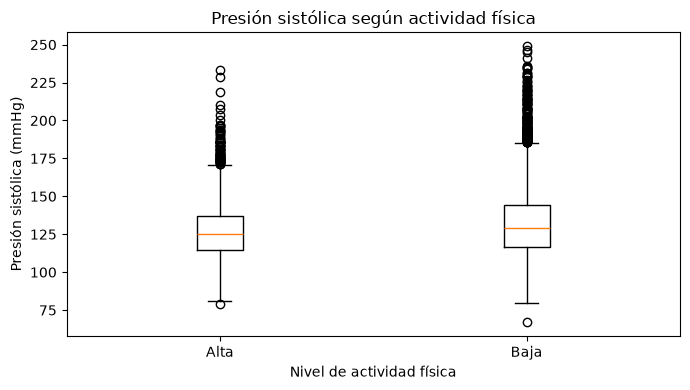

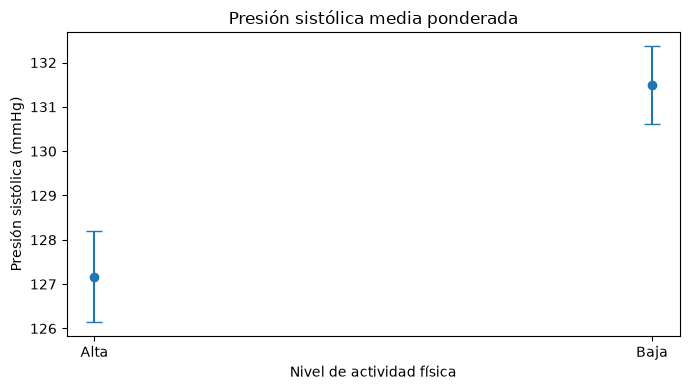


H2 - CONTRASTE ESTADÍSTICO
Método: Wald unilateral con varianza bootstrap del INDEC
Diferencia de medias (Baja - Alta): 4.3232 mmHg
Error estándar de la diferencia: 0.7610
IC 95% de la diferencia: [2.8317, 5.8147]
Estadístico Z: 5.6811
P-valor unilateral: 6.69265e-09
Nivel de significancia: 0.05


In [16]:
alpha = 0.05
columnas_rep = [f'wf2p_rep{i}' for i in range(1, 201)]

# Usamos los registros del Paso 2 y unificamos los identificadores para el cruce.
base = df_paso2[
    ['id_encuestado', 'actividad_fisica', 'presion_sistolica', 'wf2p']
].copy()

replicas = df_replicas[['id_encuestado'] + columnas_rep].copy()

for df in (base, replicas):
    df['id_encuestado'] = (
        df['id_encuestado'].astype('string')
        .str.strip().str.replace(r'\.0$', '', regex=True)
    )

datos = base.merge(
    replicas,
    on='id_encuestado',
    how='left',
    validate='one_to_one'
)

if datos[columnas_rep].isna().any().any():
    raise ValueError('Faltan pesos replicados para algunos registros.')

y = datos['presion_sistolica'].to_numpy(dtype=float)
y_valida = np.nan_to_num(y, nan=0.0)
actividad = datos['actividad_fisica'].to_numpy()
w = datos['wf2p'].to_numpy(dtype=float)
wr = datos[columnas_rep].to_numpy(dtype=float)

resultados = {}
resumen = []

# Estimamos por separado las medias de actividad alta y baja con sus réplicas.
for nivel, nombre in [(1, 'Alta'), (3, 'Baja')]:
    dominio = (
        (actividad == nivel) &
        np.isfinite(y) &
        (w > 0)
    )

    pesos = w * dominio
    pesos_rep = wr * dominio[:, None]

    media = np.sum(pesos * y_valida) / np.sum(pesos)

    denominadores = pesos_rep.sum(axis=0)

    if np.any(denominadores <= 0):
        raise ValueError(f'Denominador nulo para actividad {nombre}.')

    medias_rep = (
        (pesos_rep * y_valida[:, None]).sum(axis=0)
        / denominadores
    )

    ee = np.sqrt(np.mean((medias_rep - media) ** 2))

    resultados[nombre] = {
        'media': media,
        'ee': ee,
        'replicas': medias_rep
    }

    resumen.append({
        'Actividad física': nombre,
        'Registros': dominio.sum(),
        'Media observada': y[dominio].mean(),
        'Mediana observada': np.median(y[dominio]),
        'Media ponderada': media,
        'Error estándar': ee,
        'IC 95% inferior': media - 1.96 * ee,
        'IC 95% superior': media + 1.96 * ee,
        'CV (%)': ee / media * 100
    })

tabla = pd.DataFrame(resumen)
display(tabla.round(2))

# Gráficos de distribución y de medias ponderadas.
grupos = [
    df_h2.loc[df_h2['actividad_fisica'] == nivel, 'presion_sistolica']
    for nivel in [1, 3]
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(grupos, tick_labels=['Alta', 'Baja'])
ax.set_title('Presión sistólica según actividad física')
ax.set_ylabel('Presión sistólica (mmHg)')
ax.set_xlabel('Nivel de actividad física')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    ['Alta', 'Baja'],
    [resultados[g]['media'] for g in ['Alta', 'Baja']],
    yerr=[1.96 * resultados[g]['ee'] for g in ['Alta', 'Baja']],
    fmt='o',
    capsize=6
)
ax.set_title('Presión sistólica media ponderada')
ax.set_ylabel('Presión sistólica (mmHg)')
ax.set_xlabel('Nivel de actividad física')
plt.tight_layout()
plt.show()

# Contrastamos si la media del grupo de actividad baja es mayor.
diferencia = resultados['Baja']['media'] - resultados['Alta']['media']

diferencias_rep = (
    resultados['Baja']['replicas'] -
    resultados['Alta']['replicas']
)

ee_diferencia = np.sqrt(
    np.mean((diferencias_rep - diferencia) ** 2)
)

if ee_diferencia <= 0:
    raise ValueError('El error estándar de la diferencia no es positivo.')

z = diferencia / ee_diferencia
p_valor = norm.sf(z)

ic_inferior = diferencia - 1.96 * ee_diferencia
ic_superior = diferencia + 1.96 * ee_diferencia

print('\nH2 - CONTRASTE ESTADÍSTICO')
print('Método: Wald unilateral con varianza bootstrap del INDEC')
print(f'Diferencia de medias (Baja - Alta): {diferencia:.4f} mmHg')
print(f'Error estándar de la diferencia: {ee_diferencia:.4f}')
print(f'IC 95% de la diferencia: [{ic_inferior:.4f}, {ic_superior:.4f}]')
print(f'Estadístico Z: {z:.4f}')
print(f'P-valor unilateral: {p_valor:.6g}')
print(f'Nivel de significancia: {alpha}')

## 4.3. H3 — Consumo de frutas y verduras e IMC
Ajustamos una regresión lineal múltiple ponderada con el IMC como variable respuesta y el consumo de frutas y verduras, la edad y la actividad física como explicativas. Utilizamos los pesos replicados del Paso 2 para evaluar los coeficientes y contrastar si el coeficiente del consumo es negativo. Finalmente mostramos la relación observada y los residuos del modelo.

H3 - ANÁLISIS MULTIVARIADO
Registros válidos: 15838


,imc,consumo_diario_fv,edad
count,15838.00,15838.00,15838.00
mean,28.23,2.03,46.24
std,5.91,1.70,17.92
min,14.15,0.00,18.00
25%,24.02,1.00,31.00
50%,27.42,1.57,44.00
75%,31.56,2.57,60.00
max,86.57,17.00,104.00



Distribución por nivel de actividad física:


,Registros
Actividad física,
Baja,7396
Media,5715
Alta,2727



COEFICIENTES DEL MODELO


,Variable,Coeficiente,Error estándar,IC 95% inferior,IC 95% superior,P-valor bilateral
0,Intercepto,23.77110,0.28861,23.20542,24.33678,0.00000
1,Consumo diario FV,0.01661,0.04476,-0.07112,0.10435,0.71058
2,Edad,0.07711,0.00445,0.06838,0.08584,0.00000
3,Actividad media,0.51998,0.23520,0.05898,0.98098,0.02705
4,Actividad baja,1.39052,0.22498,0.94956,1.83148,0.00000



R² ponderado: 0.0709

H3 - CONTRASTE ESTADÍSTICO
Método: regresión lineal ponderada con varianza bootstrap
Coeficiente del consumo: 0.01661
Error estándar: 0.04476
IC 95%: [-0.07112, 0.10435]
Estadístico Z: 0.3711
P-valor unilateral: 0.644712
Nivel de significancia: 0.05


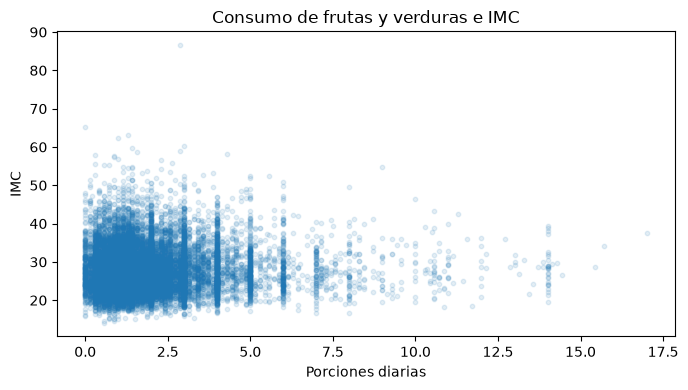

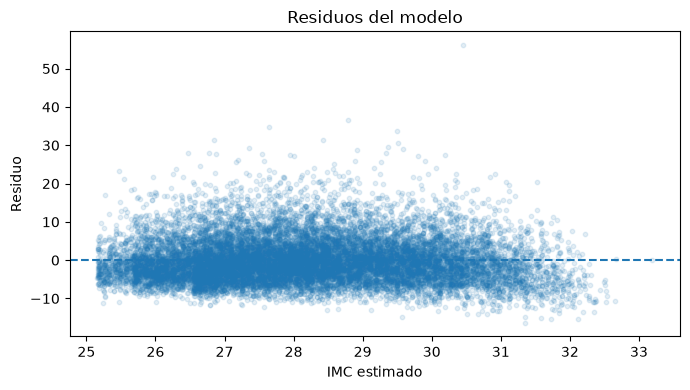

In [17]:
alpha = 0.05

variables = [
    'id_encuestado', 'imc', 'consumo_diario_fv',
    'edad', 'actividad_fisica', 'wf2p'
]
columnas_rep = [f'wf2p_rep{i}' for i in range(1, 201)]

# Seleccionamos observaciones completas y vinculamos sus pesos replicados.
datos = df_h3[variables].dropna().copy()
datos = datos[
    datos['actividad_fisica'].isin([1, 2, 3]) &
    (datos['wf2p'] > 0)
].copy()

replicas = df_replicas[['id_encuestado'] + columnas_rep].copy()

for df in (datos, replicas):
    df['id_encuestado'] = (
        df['id_encuestado'].astype('string')
        .str.strip().str.replace(r'\.0$', '', regex=True)
    )

datos = datos.merge(
    replicas,
    on='id_encuestado',
    how='left',
    validate='one_to_one'
)

if datos[columnas_rep].isna().any().any():
    raise ValueError('Faltan pesos replicados para algunos registros.')

print('H3 - ANÁLISIS MULTIVARIADO')
print(f'Registros válidos: {len(datos)}')

display(
    datos[['imc', 'consumo_diario_fv', 'edad']]
    .describe().round(2)
)

print('\nDistribución por nivel de actividad física:')
display(
    datos['actividad_fisica']
    .map({1: 'Alta', 2: 'Media', 3: 'Baja'})
    .value_counts()
    .rename_axis('Actividad física')
    .to_frame('Registros')
)

# En la regresión la actividad alta queda como categoría de referencia.

X = np.column_stack([
    np.ones(len(datos)),
    datos['consumo_diario_fv'].to_numpy(dtype=float),
    datos['edad'].to_numpy(dtype=float),
    (datos['actividad_fisica'] == 2).to_numpy(dtype=float),
    (datos['actividad_fisica'] == 3).to_numpy(dtype=float)
])

y = datos['imc'].to_numpy(dtype=float)
w = datos['wf2p'].to_numpy(dtype=float)
wr = datos[columnas_rep].to_numpy(dtype=float)

nombres = [
    'Intercepto',
    'Consumo diario FV',
    'Edad',
    'Actividad media',
    'Actividad baja'
]


def ajustar_modelo(pesos):
    raiz = np.sqrt(pesos)
    return np.linalg.lstsq(
        X * raiz[:, None],
        y * raiz,
        rcond=None
    )[0]

beta = ajustar_modelo(w)

# Repetimos el ajuste con cada réplica para estimar los errores estándar.
beta_replicas = np.array([
    ajustar_modelo(wr[:, i])
    for i in range(200)
])

ee = np.sqrt(np.mean((beta_replicas - beta) ** 2, axis=0))

if np.any(ee <= 0):
    raise ValueError('Se obtuvo un error estándar no positivo.')

z = beta / ee
p_bilateral = 2 * norm.sf(np.abs(z))

tabla_coef = pd.DataFrame({
    'Variable': nombres,
    'Coeficiente': beta,
    'Error estándar': ee,
    'IC 95% inferior': beta - 1.96 * ee,
    'IC 95% superior': beta + 1.96 * ee,
    'P-valor bilateral': p_bilateral
})

print('\nCOEFICIENTES DEL MODELO')
display(tabla_coef.round(5))

# Calculamos el R² ponderado del modelo.

predicciones = X @ beta
residuos = y - predicciones

media_y = np.average(y, weights=w)

r2 = 1 - (
    np.sum(w * residuos**2) /
    np.sum(w * (y - media_y)**2)
)

print(f'\nR² ponderado: {r2:.4f}')

# Contrastamos si el coeficiente del consumo es negativo.

coef_consumo = beta[1]
ee_consumo = ee[1]
z_consumo = coef_consumo / ee_consumo
p_unilateral = norm.cdf(z_consumo)

print('\nH3 - CONTRASTE ESTADÍSTICO')
print('Método: regresión lineal ponderada con varianza bootstrap')
print(f'Coeficiente del consumo: {coef_consumo:.5f}')
print(f'Error estándar: {ee_consumo:.5f}')
print(
    f'IC 95%: [{coef_consumo - 1.96 * ee_consumo:.5f}, '
    f'{coef_consumo + 1.96 * ee_consumo:.5f}]'
)
print(f'Estadístico Z: {z_consumo:.4f}')
print(f'P-valor unilateral: {p_unilateral:.6g}')
print(f'Nivel de significancia: {alpha}')

# Visualizamos la relación observada y los residuos del modelo.

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(
    datos['consumo_diario_fv'],
    datos['imc'],
    alpha=0.12,
    s=10
)
ax.set_title('Consumo de frutas y verduras e IMC')
ax.set_xlabel('Porciones diarias')
ax.set_ylabel('IMC')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(predicciones, residuos, alpha=0.12, s=10)
ax.axhline(0, linestyle='--')
ax.set_title('Residuos del modelo')
ax.set_xlabel('IMC estimado')
ax.set_ylabel('Residuo')
plt.tight_layout()
plt.show()

## 4.4. H4 — Consumo diario de frutas y verduras

### 4.4.1. Preparación de los pesos replicados del Paso 1
Extraemos de la misma base del INDEC los 200 pesos replicados del Paso 1 (wf1p_rep1 a wf1p_rep200) para realizar la inferencia sobre el consumo diario de frutas y verduras.

In [18]:
ruta = Path('base_replicas_enfr2018.zip')
if not ruta.exists() and Path('datos/base_replicas_enfr2018.zip').exists():
    ruta = Path('datos/base_replicas_enfr2018.zip')
columnas_rep1 = [f'wf1p_rep{i}' for i in range(1, 201)]

# Extraemos los pesos replicados del Paso 1 del archivo ya descargado.
with ZipFile(ruta) as archivo:
    nombres = [
        n for n in archivo.namelist()
        if n.lower().endswith(('.txt', '.csv'))
    ]

    nombre = next(
        (n for n in nombres if 'rep' in n.lower()),
        nombres[0]
    )

    with archivo.open(nombre) as contenido:
        df_replicas_p1 = pd.read_csv(
            contenido,
            sep='|',
            usecols=lambda c: c.strip().lower() in (
                ['id'] + columnas_rep1
            )
        )

df_replicas_p1.columns = (
    df_replicas_p1.columns.str.strip().str.lower()
)

df_replicas_p1.rename(
    columns={'id': 'id_encuestado'},
    inplace=True
)

# Verificamos la disponibilidad de las 200 réplicas.
assert all(c in df_replicas_p1.columns for c in columnas_rep1)
assert df_replicas_p1['id_encuestado'].is_unique

print(f'Registros: {len(df_replicas_p1)}')
print(f'Pesos replicados disponibles: {len(columnas_rep1)}')

Registros: 29224
Pesos replicados disponibles: 200


/tmp/ipykernel_282205/477865580.py:31: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_replicas_p1.rename(


### 4.4.2. Análisis y contraste de la media
Mostramos la distribución del consumo diario y calculamos su media ponderada con wf1p. Después estimamos el error estándar y el intervalo de confianza mediante las réplicas del Paso 1 y contrastamos si la media poblacional es inferior a cinco porciones diarias.

H4 - ANÁLISIS EXPLORATORIO


,Indicador,Valor
0,Registros válidos,28471.0000
1,Media observada,2.0712
2,Mediana observada,1.6400
3,Media ponderada,2.0297
4,Desvío estándar observado,1.7083
5,Mínimo,0.0000
6,Máximo,18.0000
7,Porcentaje ponderado inferior a 5,93.9562


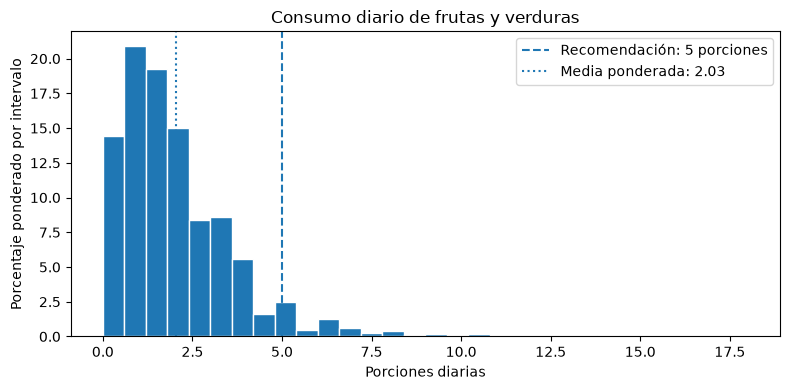


H4 - CONTRASTE ESTADÍSTICO
Método: Wald unilateral con varianza bootstrap del INDEC
Media ponderada: 2.0297 porciones
Diferencia respecto de 5: -2.9703
Error estándar bootstrap: 0.019344
IC 95%: [1.9918, 2.0676]
Coeficiente de variación: 0.95%
Estadístico Z: -153.5555
P-valor unilateral: < 1e-300
Nivel de significancia: 0.05


In [19]:
alpha = 0.05
mu0 = 5
columnas_rep = [f'wf1p_rep{i}' for i in range(1, 201)]

# Incorporamos los pesos replicados a los registros válidos de consumo.
datos = df_h4.copy()
replicas = df_replicas_p1[['id_encuestado'] + columnas_rep].copy()

for df in (datos, replicas):
    df['id_encuestado'] = (
        df['id_encuestado'].astype('string')
        .str.strip().str.replace(r'\.0$', '', regex=True)
    )

datos = datos.merge(
    replicas,
    on='id_encuestado',
    how='left',
    validate='one_to_one'
)

if datos[columnas_rep].isna().any().any():
    raise ValueError('Faltan pesos replicados para algunos registros.')

y = datos['consumo_diario_fv'].to_numpy(dtype=float)
w = datos['wf1p'].to_numpy(dtype=float)
wr = datos[columnas_rep].to_numpy(dtype=float)

validos = np.isfinite(y) & np.isfinite(w) & (w > 0)

if not validos.all():
    raise ValueError('Existen consumos o factores de expansión inválidos.')

# Resumimos el consumo observado y el estimado con ponderadores.

media_observada = np.mean(y)
mediana_observada = np.median(y)
media_ponderada = np.average(y, weights=w)
porcentaje_inferior = np.average(y < mu0, weights=w) * 100

print('H4 - ANÁLISIS EXPLORATORIO')

resumen = pd.DataFrame({
    'Indicador': [
        'Registros válidos',
        'Media observada',
        'Mediana observada',
        'Media ponderada',
        'Desvío estándar observado',
        'Mínimo',
        'Máximo',
        'Porcentaje ponderado inferior a 5'
    ],
    'Valor': [
        len(y),
        media_observada,
        mediana_observada,
        media_ponderada,
        np.std(y, ddof=1),
        np.min(y),
        np.max(y),
        porcentaje_inferior
    ]
})

display(resumen.round(4))

# Graficamos el consumo ponderado y la referencia de cinco porciones.

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    y,
    bins=30,
    weights=w / w.sum() * 100,
    edgecolor='white'
)

ax.axvline(
    mu0,
    linestyle='--',
    label='Recomendación: 5 porciones'
)

ax.axvline(
    media_ponderada,
    linestyle=':',
    label=f'Media ponderada: {media_ponderada:.2f}'
)

ax.set_title('Consumo diario de frutas y verduras')
ax.set_xlabel('Porciones diarias')
ax.set_ylabel('Porcentaje ponderado por intervalo')
ax.legend()

plt.tight_layout()
plt.show()

# Estimamos la variabilidad de la media usando las 200 réplicas.

denominadores = wr.sum(axis=0)

if np.any(denominadores <= 0):
    raise ValueError('Una réplica tiene denominador nulo.')

medias_rep = (wr.T @ y) / denominadores

varianza = np.mean((medias_rep - media_ponderada) ** 2)
ee = np.sqrt(varianza)

if ee <= 0:
    raise ValueError('El error estándar no es positivo.')

ic_inferior = media_ponderada - 1.96 * ee
ic_superior = media_ponderada + 1.96 * ee
cv = ee / media_ponderada * 100

# Contrastamos si la media poblacional es menor que cinco.

z = (media_ponderada - mu0) / ee
log_p = norm.logcdf(z)

p_valor = (
    f'{np.exp(log_p):.6g}'
    if log_p >= np.log(1e-300)
    else '< 1e-300'
)

print('\nH4 - CONTRASTE ESTADÍSTICO')
print('Método: Wald unilateral con varianza bootstrap del INDEC')
print(f'Media ponderada: {media_ponderada:.4f} porciones')
print(f'Diferencia respecto de 5: {media_ponderada - mu0:.4f}')
print(f'Error estándar bootstrap: {ee:.6f}')
print(f'IC 95%: [{ic_inferior:.4f}, {ic_superior:.4f}]')
print(f'Coeficiente de variación: {cv:.2f}%')
print(f'Estadístico Z: {z:.4f}')
print(f'P-valor unilateral: {p_valor}')
print(f'Nivel de significancia: {alpha}')

## 4.5. H5 — IMC y nivel de actividad física
Comparamos el IMC medido entre los tres niveles de actividad física. Calculamos las medias ponderadas y sus intervalos de confianza con wf2p y sus réplicas. Luego realizamos un contraste global de igualdad de medias y mostramos comparaciones exploratorias entre pares de grupos.

H5 - ANÁLISIS EXPLORATORIO
Registros válidos: 16282


,Actividad física,Registros,Media observada,Mediana observada,Desvío observado,Media ponderada,Error estándar,IC 95% inferior,IC 95% superior,CV (%)
0,Alta,2768,26.950,26.15,5.353,26.691,0.189,26.322,27.061,0.706
1,Media,5840,27.825,27.06,5.560,27.675,0.126,27.429,27.922,0.454
2,Baja,7674,28.985,28.23,6.266,28.808,0.133,28.547,29.069,0.462


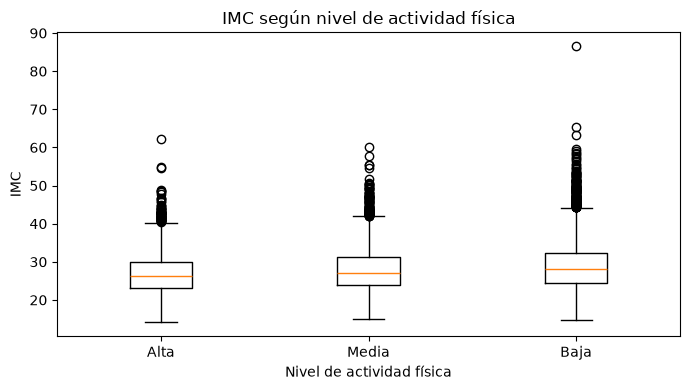

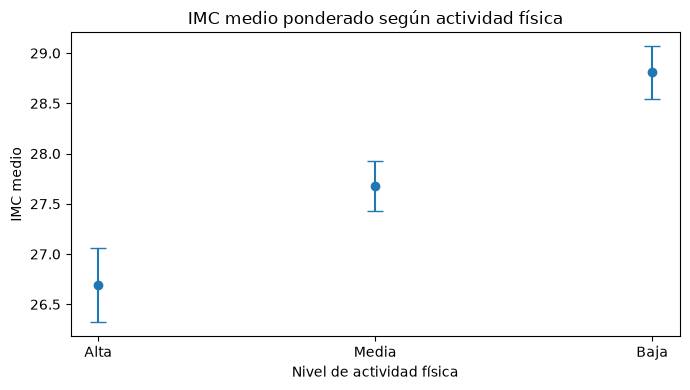


H5 - CONTRASTE GLOBAL
Método: Wald con varianza bootstrap del INDEC
Estadístico Wald: 100.3233
Grados de libertad: 2
P-valor: 1.64088e-22
Nivel de significancia: 0.05

COMPARACIONES ENTRE GRUPOS (EXPLORATORIAS)


,Comparación,Diferencia,Error estándar,IC 95% inferior,IC 95% superior,P-valor bilateral
0,Media - Alta,0.98389,0.24558,0.50254,1.46523,0.00006
1,Baja - Alta,2.11699,0.22732,1.67144,2.56254,0.00000
2,Baja - Media,1.13311,0.18109,0.77818,1.48803,0.00000


In [20]:
alpha = 0.05
columnas_rep = [f'wf2p_rep{i}' for i in range(1, 201)]

# Vinculamos cada registro con sus pesos replicados del Paso 2.
datos = df_h5.copy()
replicas = df_replicas[['id_encuestado'] + columnas_rep].copy()

for df in (datos, replicas):
    df['id_encuestado'] = (
        df['id_encuestado'].astype('string')
        .str.strip().str.replace(r'\.0$', '', regex=True)
    )

datos = datos.merge(
    replicas,
    on='id_encuestado',
    how='left',
    validate='one_to_one'
)

if datos[columnas_rep].isna().any().any():
    raise ValueError('Faltan pesos replicados.')

datos = datos[
    datos['actividad_fisica'].isin([1, 2, 3]) &
    datos['imc'].notna() &
    (datos['wf2p'] > 0)
].copy()

y = datos['imc'].to_numpy(dtype=float)
w = datos['wf2p'].to_numpy(dtype=float)
wr = datos[columnas_rep].to_numpy(dtype=float)
actividad = datos['actividad_fisica'].to_numpy()

niveles = [(1, 'Alta'), (2, 'Media'), (3, 'Baja')]

medias = []
medias_rep = []
resumen = []

# Calculamos las medias y la variabilidad para cada nivel de actividad.
for codigo, nombre in niveles:
    grupo = actividad == codigo

    media = np.average(y[grupo], weights=w[grupo])

    pesos_rep = wr[grupo]
    denominadores = pesos_rep.sum(axis=0)

    if np.any(denominadores <= 0):
        raise ValueError(f'Denominador nulo en actividad {nombre}.')

    replicas_media = (
        pesos_rep.T @ y[grupo]
    ) / denominadores

    ee = np.sqrt(np.mean((replicas_media - media) ** 2))

    medias.append(media)
    medias_rep.append(replicas_media)

    resumen.append({
        'Actividad física': nombre,
        'Registros': grupo.sum(),
        'Media observada': np.mean(y[grupo]),
        'Mediana observada': np.median(y[grupo]),
        'Desvío observado': np.std(y[grupo], ddof=1),
        'Media ponderada': media,
        'Error estándar': ee,
        'IC 95% inferior': media - 1.96 * ee,
        'IC 95% superior': media + 1.96 * ee,
        'CV (%)': ee / media * 100
    })

medias = np.array(medias)
medias_rep = np.column_stack(medias_rep)

print('H5 - ANÁLISIS EXPLORATORIO')
print(f'Registros válidos: {len(datos)}')

tabla = pd.DataFrame(resumen)
display(tabla.round(3))

fig, ax = plt.subplots(figsize=(7, 4))

grupos = [y[actividad == codigo] for codigo, _ in niveles]

ax.boxplot(grupos, tick_labels=['Alta', 'Media', 'Baja'])
ax.set_title('IMC según nivel de actividad física')
ax.set_xlabel('Nivel de actividad física')
ax.set_ylabel('IMC')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))

ax.errorbar(
    ['Alta', 'Media', 'Baja'],
    medias,
    yerr=1.96 * tabla['Error estándar'].to_numpy(),
    fmt='o',
    capsize=6
)

ax.set_title('IMC medio ponderado según actividad física')
ax.set_xlabel('Nivel de actividad física')
ax.set_ylabel('IMC medio')

plt.tight_layout()
plt.show()

# Contrastamos conjuntamente la igualdad de las tres medias.

diferencias = np.array([
    medias[1] - medias[0],
    medias[2] - medias[0]
])

diferencias_rep = np.column_stack([
    medias_rep[:, 1] - medias_rep[:, 0],
    medias_rep[:, 2] - medias_rep[:, 0]
])

desviaciones = diferencias_rep - diferencias

covarianza = desviaciones.T @ desviaciones / 200

if np.linalg.matrix_rank(covarianza) < 2:
    raise ValueError('La matriz de covarianza no tiene rango completo.')

wald = diferencias @ np.linalg.solve(covarianza, diferencias)
p_valor = chi2.sf(wald, df=2)

print('\nH5 - CONTRASTE GLOBAL')
print('Método: Wald con varianza bootstrap del INDEC')
print(f'Estadístico Wald: {wald:.4f}')
print('Grados de libertad: 2')
print(f'P-valor: {p_valor:.6g}')
print(f'Nivel de significancia: {alpha}')

# Exploramos las diferencias entre pares de grupos.

comparaciones = []

for i, j in [(0, 1), (0, 2), (1, 2)]:
    diferencia = medias[j] - medias[i]
    replica_diferencia = medias_rep[:, j] - medias_rep[:, i]

    ee = np.sqrt(
        np.mean((replica_diferencia - diferencia) ** 2)
    )

    z = diferencia / ee
    p = 2 * norm.sf(abs(z))

    comparaciones.append({
        'Comparación': f'{niveles[j][1]} - {niveles[i][1]}',
        'Diferencia': diferencia,
        'Error estándar': ee,
        'IC 95% inferior': diferencia - 1.96 * ee,
        'IC 95% superior': diferencia + 1.96 * ee,
        'P-valor bilateral': p
    })

tabla_comparaciones = pd.DataFrame(comparaciones)

print('\nCOMPARACIONES ENTRE GRUPOS (EXPLORATORIAS)')
display(tabla_comparaciones.round(5))

## 4.6. H6 — Glucemia, IMC, presión sistólica, cintura y edad


### 4.6.1. Preparación de los pesos replicados del Paso 3
Seleccionamos los 200 pesos replicados del Paso 3 (wf3p_rep1 a wf3p_rep200), correspondientes a las mediciones bioquímicas. Se utilizarán para estimar la variabilidad de los coeficientes del modelo.

In [21]:
ruta = Path('base_replicas_enfr2018.zip')
if not ruta.exists() and Path('datos/base_replicas_enfr2018.zip').exists():
    ruta = Path('datos/base_replicas_enfr2018.zip')
columnas_rep3 = [f'wf3p_rep{i}' for i in range(1, 201)]

# Recuperamos las réplicas del Paso 3 para las mediciones bioquímicas.
with ZipFile(ruta) as archivo:
    nombres = [
        n for n in archivo.namelist()
        if n.lower().endswith(('.txt', '.csv'))
    ]
    nombre = next((n for n in nombres if 'rep' in n.lower()), nombres[0])

    with archivo.open(nombre) as contenido:
        df_replicas_p3 = pd.read_csv(
            contenido,
            sep='|',
            usecols=lambda c: c.strip().lower() in (['id'] + columnas_rep3)
        )

df_replicas_p3.columns = df_replicas_p3.columns.str.strip().str.lower()
df_replicas_p3.rename(columns={'id': 'id_encuestado'}, inplace=True)

# Verificamos que estén disponibles los 200 pesos y sus identificadores.
assert all(c in df_replicas_p3.columns for c in columnas_rep3)
assert df_replicas_p3['id_encuestado'].is_unique

print(f'Registros: {len(df_replicas_p3)}')
print(f'Pesos replicados disponibles: {len(columnas_rep3)}')

Registros: 29224
Pesos replicados disponibles: 200


/tmp/ipykernel_282205/192247728.py:22: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_replicas_p3.rename(columns={'id': 'id_encuestado'}, inplace=True)


### 4.6.2. Regresión lineal múltiple y contraste global
Ajustamos una regresión ponderada para analizar la relación entre la glucemia en ayunas y el IMC, la presión sistólica, el perímetro de cintura y la edad. Calculamos los coeficientes, sus errores estándar y un contraste global con los pesos replicados del Paso 3. También mostramos el R², los VIF y los gráficos de residuos.

H6 - ANÁLISIS EXPLORATORIO
Registros válidos: 5039


,glucemia_mg_dl,imc,presion_sistolica,cintura_cm,edad
count,5039.00,5039.00,5039.00,5039.00,5039.00
mean,80.76,28.19,129.95,92.17,46.25
std,30.86,5.86,20.89,16.01,17.92
min,20.00,15.82,67.00,49.00,18.00
25%,65.00,24.01,115.00,81.00,31.00
50%,79.00,27.36,126.50,92.00,44.00
75%,92.00,31.46,141.00,102.00,60.00
max,382.00,65.31,245.00,209.00,97.00



COEFICIENTES DEL MODELO


,Variable,Coeficiente,Error estándar,IC 95% inferior,IC 95% superior,P-valor bilateral
0,Intercepto,36.22919,4.72517,26.96786,45.49052,0.00000
1,imc,0.02586,0.23064,-0.42620,0.47791,0.91074
2,presion_sistolica,0.06274,0.04173,-0.01905,0.14453,0.13270
3,cintura_cm,0.27191,0.08524,0.10483,0.43899,0.00142
4,edad,0.21003,0.04296,0.12583,0.29423,0.00000



R² ponderado: 0.0627

MULTICOLINEALIDAD


,Variable,VIF
0,imc,3.101
1,presion_sistolica,1.372
2,cintura_cm,3.346
3,edad,1.373



H6 - CONTRASTE GLOBAL
Método: Wald con varianza bootstrap del INDEC
Estadístico Wald: 142.7921
Grados de libertad: 4
P-valor: 7.12515e-30
Nivel de significancia: 0.05


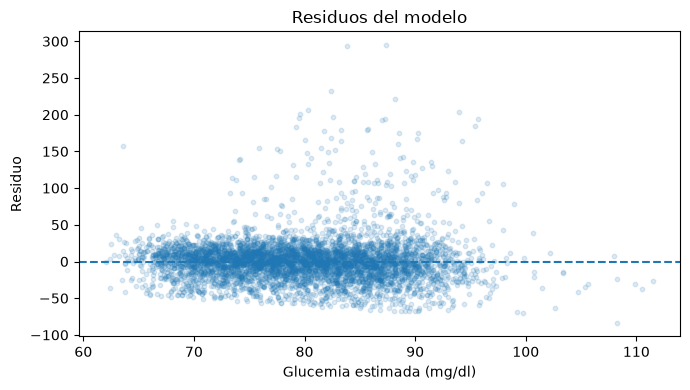

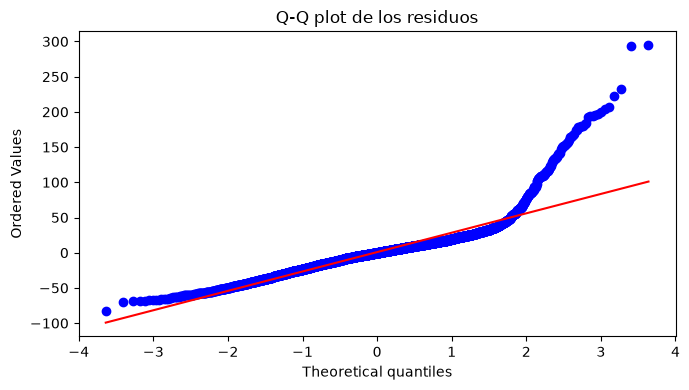

In [22]:
alpha = 0.05

explicativas = ['imc', 'presion_sistolica', 'cintura_cm', 'edad']
objetivo = 'glucemia_mg_dl'
columnas_rep = [f'wf3p_rep{i}' for i in range(1, 201)]

columnas = ['id_encuestado', objetivo] + explicativas + ['wf3p']
# Seleccionamos los registros completos e incorporamos los pesos replicados.
datos = df_h6[columnas].dropna().copy()
replicas = df_replicas_p3[['id_encuestado'] + columnas_rep].copy()

for df in (datos, replicas):
    df['id_encuestado'] = (
        df['id_encuestado'].astype('string')
        .str.strip().str.replace(r'\.0$', '', regex=True)
    )

datos = datos.merge(
    replicas,
    on='id_encuestado',
    how='left',
    validate='one_to_one'
)

if datos[columnas_rep].isna().any().any():
    raise ValueError('Faltan pesos replicados para algunos registros.')

datos = datos[datos['wf3p'] > 0].copy()

print('H6 - ANÁLISIS EXPLORATORIO')
print(f'Registros válidos: {len(datos)}')

display(datos[[objetivo] + explicativas].describe().round(2))

# Ajustamos la regresión ponderada con glucemia como respuesta.

X = np.column_stack([
    np.ones(len(datos)),
    datos[explicativas].to_numpy(dtype=float)
])

y = datos[objetivo].to_numpy(dtype=float)
w = datos['wf3p'].to_numpy(dtype=float)
wr = datos[columnas_rep].to_numpy(dtype=float)

if not np.isfinite(X).all() or not np.isfinite(y).all():
    raise ValueError('Existen valores no finitos en el modelo.')

if not np.isfinite(wr).all() or (wr < 0).any():
    raise ValueError('Existen pesos replicados inválidos.')

if np.linalg.matrix_rank(X) < X.shape[1]:
    raise ValueError('El modelo presenta dependencia lineal exacta.')


def ajustar_modelo(pesos):
    raiz = np.sqrt(pesos)
    return np.linalg.lstsq(
        X * raiz[:, None],
        y * raiz,
        rcond=None
    )[0]

beta = ajustar_modelo(w)

# Estimamos los coeficientes en cada réplica para calcular su covarianza.
beta_replicas = np.array([
    ajustar_modelo(wr[:, i])
    for i in range(200)
])

desviaciones = beta_replicas - beta
covarianza = desviaciones.T @ desviaciones / 200
ee = np.sqrt(np.diag(covarianza))

if np.any(ee <= 0):
    raise ValueError('Se obtuvo un error estándar no positivo.')

z = beta / ee
p_bilateral = 2 * norm.sf(np.abs(z))

nombres = ['Intercepto'] + explicativas

tabla_coef = pd.DataFrame({
    'Variable': nombres,
    'Coeficiente': beta,
    'Error estándar': ee,
    'IC 95% inferior': beta - 1.96 * ee,
    'IC 95% superior': beta + 1.96 * ee,
    'P-valor bilateral': p_bilateral
})

print('\nCOEFICIENTES DEL MODELO')
display(tabla_coef.round(5))

# Calculamos el R² ponderado para resumir el ajuste.

predicciones = X @ beta
residuos = y - predicciones
media_y = np.average(y, weights=w)

r2 = 1 - (
    np.sum(w * residuos**2) /
    np.sum(w * (y - media_y)**2)
)

print(f'\nR² ponderado: {r2:.4f}')

# Calculamos los VIF de las variables explicativas.

vif = []

for j, variable in enumerate(explicativas, start=1):
    x_j = X[:, j]
    X_otros = np.delete(X, j, axis=1)

    raiz = np.sqrt(w)
    b = np.linalg.lstsq(
        X_otros * raiz[:, None],
        x_j * raiz,
        rcond=None
    )[0]

    error = x_j - X_otros @ b

    r2_j = 1 - (
        np.sum(w * error**2) /
        np.sum(w * (x_j - np.average(x_j, weights=w))**2)
    )

    vif.append({
        'Variable': variable,
        'VIF': 1 / (1 - r2_j)
    })

print('\nMULTICOLINEALIDAD')
display(pd.DataFrame(vif).round(3))

# Contrastamos si los cuatro coeficientes son conjuntamente cero.

coeficientes = beta[1:]
cov_pendientes = covarianza[1:, 1:]

if np.linalg.matrix_rank(cov_pendientes) < 4:
    raise ValueError('La matriz de covarianza no tiene rango completo.')

wald = coeficientes @ np.linalg.solve(
    cov_pendientes, coeficientes
)

p_global = chi2.sf(wald, df=4)

print('\nH6 - CONTRASTE GLOBAL')
print('Método: Wald con varianza bootstrap del INDEC')
print(f'Estadístico Wald: {wald:.4f}')
print('Grados de libertad: 4')
print(f'P-valor: {p_global:.6g}')
print(f'Nivel de significancia: {alpha}')

# Revisamos los residuos y su distribución.

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(predicciones, residuos, alpha=0.15, s=10)
ax.axhline(0, linestyle='--')
ax.set_title('Residuos del modelo')
ax.set_xlabel('Glucemia estimada (mg/dl)')
ax.set_ylabel('Residuo')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
probplot(residuos, dist='norm', plot=ax)
ax.set_title('Q-Q plot de los residuos')
plt.tight_layout()
plt.show()